# Organ weights, gut lesions and breast meat with dietary cricket meal

## 1. Introduction

The first notebook (`01_growth_feed_efficiency.ipynb`) covered growth and feed efficiency, which is one of the six sheets of the workbook. This notebook works through the other five: organ weights, intestinal lesion scores, breast meat yield and colour, cooking loss and texture. The question is:

**Did cricket meal change the birds' organs, gut lesions or breast meat?**

The approach is the same as before. Each sheet is inspected as it is and cleaned only where the inspection shows a problem. Every calculation that the workbook supplies (organ indices, yields, averages, frequency tables) is done again from the measurements and compared.

## 2. Data and sampling design

The source is the same as in the first notebook: Mendeley Data, [doi:10.17632/rj5fybnzh6.1](https://doi.org/10.17632/rj5fybnzh6.1) (version 1, CC BY 4.0). The trial had six diets with four pens each: a non-medicated control (0% NM), a medicated control (0% M), and 5, 10, 15 and 20% cricket meal (CM). According to the dataset description, organ indices were calculated for three birds per pen on days 13, 20 and 35, and meat quality was analysed on day 35.

Two points decide how these sheets have to be analysed:

- **The sampled birds are not the experimental unit.** Diets were given to pens, so the pen is still the unit. The three birds taken from a pen are averaged first, and diets are compared on the pen means (four per diet). Treating 72 birds as 72 independent observations would overstate the evidence.
- **Different birds at each age.** An organ can only be weighed once, so days 13, 20 and 35 are three separate samples and not repeated measurements on the same birds.

## 3. Imports and settings

In [1]:
import hashlib
import platform
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import scipy
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA_FILE = Path("data") / "H Fisher Growth 22 - Open access.xlsx"
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

## 4. Loading the workbook

The workbook is not stored in this repository (see `data/README.md`). On Colab the next cell asks for it once and saves it under `data/`. The file is only read. Nothing is ever written back to it.

In [2]:
if not DATA_FILE.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Download the workbook from Mendeley Data and save it as '{DATA_FILE}'") from None
    uploaded = files.upload()
    DATA_FILE.parent.mkdir(exist_ok=True)
    DATA_FILE.write_bytes(next(iter(uploaded.values())))

print("Workbook:", DATA_FILE.name)
print("SHA-256 :", hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())

Workbook: H Fisher Growth 22 - Open access.xlsx
SHA-256 : 2c0e12849a7441e66ee190f0c438d84d914ceae9d51b9b97367f64ec5737a118


In [3]:
# header=None reads every cell where it sits in the spreadsheet, without guessing which row holds the column names
sheets_raw = pd.read_excel(DATA_FILE, sheet_name=None, header=None)

# Read a second time with openpyxl, which shows merged cells and formulas as they are stored
workbook = openpyxl.load_workbook(DATA_FILE)

pd.DataFrame(
    [(name, sheet.shape[0], sheet.shape[1], len(workbook[name].merged_cells.ranges),
      sum(cell.data_type == "f" for row in workbook[name].iter_rows() for cell in row))
     for name, sheet in sheets_raw.items()],
    columns=["sheet", "rows", "columns", "merged cell ranges", "cells holding a formula"],
)

,sheet,rows,columns,merged cell ranges,cells holding a formula
0,Growth data,157,37,0,0
1,Organ weights and indices,228,19,0,214
2,"Meat yield, breast & liver Lab",84,28,9,0
3,Meat cook yield,84,9,0,0
4,Meat texture,301,7,1,0
5,Intestinal lesion scores,157,42,6,168


Six sheets. `Growth data` was analysed in the first notebook. The other five are handled here, one section each (sections 5 to 9). Three things in this overview matter for reading them:

- All five start with the same key to the treatment codes, and the column labels come further down. Each table is therefore cut out below its row of labels.
- Three sheets have merged cells. A merged title only fills the first cell of its range.
- Two sheets hold formulas. A formula is read as its last stored result, and a typed number next to it looks the same. So wherever the workbook supplies a calculation, I do it again.

Rows and columns are counted from zero in this notebook, as pandas shows them. A spreadsheet address such as Q75 is written with its letter.

In [4]:
diet_names = {1: "0% NM", 2: "0% M", 3: "5% CM", 4: "10% CM", 5: "15% CM", 6: "20% CM"}
diet_order = list(diet_names.values())


def cut_table(sheet_name, first_label, n_columns=None):
    """The data table of a sheet: the rows below the row of column labels, with the original labels kept."""
    raw = sheets_raw[sheet_name]
    label_row = raw.index[raw[0] == first_label][0]
    table = raw.iloc[label_row + 1:, :n_columns].copy()
    table.columns = raw.iloc[label_row, :n_columns].tolist()
    return table.reset_index(drop=True)


def cell_types(table):
    """What each column holds, counted cell by cell. A numeric column with a few text cells is easy to miss otherwise."""
    def count(test):
        return table.apply(lambda column: column.map(test).sum())

    return pd.DataFrame({
        "whole numbers": count(lambda value: isinstance(value, int)),
        "decimals": count(lambda value: isinstance(value, float) and not np.isnan(value)),
        "text": count(lambda value: isinstance(value, str)),
        "empty cells": count(lambda value: isinstance(value, float) and np.isnan(value)),
    })


def text_entries(table):
    """The distinct text entries of every column that holds text, with the number of cells for each."""
    entries = {}
    for column in table.columns:
        text = table.loc[table[column].map(lambda value: isinstance(value, str)), column]
        if len(text):
            entries[column] = dict(sorted(Counter(text).items()))
    return entries

The pen is the link between all sheets. The first notebook established which pens belong to which treatment from the 35-day totals table of the growth sheet (columns 27 and 28 of that sheet, which are AB and AC in the spreadsheet). The same key is read here and used to check the pen and treatment columns of every other sheet.

In [5]:
growth = sheets_raw["Growth data"]
label_row = growth.index[growth[0] == "Pen"][0]
print("Labels of the two columns used:", growth.iloc[label_row, [27, 28]].tolist())

pen_key = growth.iloc[label_row + 1:, [27, 28]].dropna()
pen_key.columns = ["pen", "treatment"]
pen_key = pen_key.astype(int).set_index("pen")["treatment"]

pen_key.reset_index().groupby("treatment")["pen"].agg(list).rename(index=diet_names).to_frame("pens")

Labels of the two columns used: ['Pen', 'Treatment ']


,pens
treatment,
0% NM,"[1, 7, 9, 21]"
0% M,"[2, 3, 18, 20]"
5% CM,"[6, 15, 17, 19]"
10% CM,"[4, 5, 10, 11]"
15% CM,"[8, 12, 22, 23]"
20% CM,"[13, 14, 16, 24]"


## 5. Organ weights (sheet `Organ weights and indices`)

### 5.1 Audit

In [6]:
organ_raw = cut_table("Organ weights and indices", "Pen")
print("Rows:", len(organ_raw), "  Columns:", organ_raw.shape[1])
print(list(organ_raw.columns))
organ_raw.head(4)

Rows: 216   Columns: 19
['Pen', 'Treatment', 'Bird ', 'Day ', 'Sex', 'Body weight (g)', 'Small intestine weight (g) ', 'Pancreas weight (g)', 'Liver weight (g)', 'Spleen weight (g)', 'Crop weight (g)', 'Bursa of Fabricius weight (g)', '% Small intestine weight (of body weight)', '% Pancreas weight (of body weight)', '% Liver weight (of body weight)', '% Spleen weight (of body weight)', '% Crop weight (of body weight)', '% Bursa of Fabricius weight (of body weight)', 'Ileal content pH']


,Pen,Treatment,Bird,Day,Sex,Body weight (g),Small intestine weight (g),Pancreas weight (g),Liver weight (g),Spleen weight (g),Crop weight (g),Bursa of Fabricius weight (g),% Small intestine weight (of body weight),% Pancreas weight (of body weight),% Liver weight (of body weight),% Spleen weight (of body weight),% Crop weight (of body weight),% Bursa of Fabricius weight (of body weight),Ileal content pH
0,1,1,1,13,F,330,34.46,1.79,10.05,0.29,1.79,0.45,10.442424,0.542424,3.045455,0.087879,0.542424,0.136364,7.78
1,1,1,2,13,M,398,35.2,1.65,13.5,0.44,3.54,0.87,8.844221,0.414573,3.39196,0.110553,0.889447,0.218593,6.37
2,1,1,3,13,M,325,38.79,1.58,11.07,0.41,4.96,0.74,11.935385,0.486154,3.406154,0.126154,1.526154,0.227692,6.65
3,2,2,1,13,F,305,26.79,1.57,9.95,0.18,3.84,0.38,8.783607,0.514754,3.262295,0.059016,1.259016,0.12459,6.93


In [7]:
cell_types(organ_raw)

,whole numbers,decimals,text,empty cells
Pen,216,0,0,0
Treatment,216,0,0,0
Bird,216,0,0,0
Day,216,0,0,0
Sex,0,0,216,0
Body weight (g),216,0,0,0
Small intestine weight (g),3,205,8,0
Pancreas weight (g),3,212,1,0
Liver weight (g),2,214,0,0
Spleen weight (g),0,216,0,0


In [8]:
for column, entries in text_entries(organ_raw).items():
    print(f"{column!r:48s}", entries)
print()
print("Duplicate rows:", organ_raw.duplicated().sum())
print("Duplicate bird records (same pen, bird and day):", organ_raw.duplicated(["Pen", "Bird ", "Day "]).sum())
print("Birds per pen at each age:", organ_raw.groupby(["Day ", "Pen"]).size().unique().tolist())
organ_raw.groupby("Day ")["Pen"].agg(pens="nunique", birds="size")

'Sex'                                            {'F': 89, 'M': 127}
'Small intestine weight (g) '                    {'.': 8}
'Pancreas weight (g)'                            {'.': 1}
'% Small intestine weight (of body weight)'      {'.': 8}
'% Pancreas weight (of body weight)'             {'.': 1}
'% Spleen weight (of body weight)'               {'.': 1}
'Ileal content pH'                               {'.': 2}

Duplicate rows: 0
Duplicate bird records (same pen, bird and day): 0
Birds per pen at each age: [3]


,pens,birds
Day,,
13,24,72
20,24,72
35,24,72


216 rows: three birds from each of the 24 pens at each of the three ages, with no duplicates. No cell is empty, but 21 cells hold a full stop: 8 small-intestine weights with their 8 indices, one pancreas weight with its index, two pH readings, and one spleen index whose weight is present. Section 5.4 looks at that last one.

Some labels carry stray spaces (`'Bird '`, `'Day '`, `'Small intestine weight (g) '`).

The overview in section 4 counted 214 formula cells in this sheet. Where are they?

In [9]:
organ_formulas = {cell.coordinate: cell.value
                  for row in workbook["Organ weights and indices"].iter_rows() for cell in row if cell.data_type == "f"}

by_column = Counter(coordinate.rstrip("0123456789") for coordinate in organ_formulas)
print("Formula cells by spreadsheet column:", dict(sorted(by_column.items())))
print("A typical formula, cell M13:", organ_formulas["M13"])
print("Formulas that do not divide by body weight (column F):",
      {coordinate: formula for coordinate, formula in organ_formulas.items() if "/F" not in formula})

Formula cells by spreadsheet column: {'M': 208, 'N': 1, 'O': 1, 'P': 1, 'Q': 2, 'R': 1}
A typical formula, cell M13: =SUM(G13/F13)*100
Formulas that do not divide by body weight (column F): {'Q75': '=P75/A75*100'}


The small-intestine index (spreadsheet column M) is a formula in every row that has an intestine weight. The other index columns are typed numbers, except in two rows. One of these formulas is wrong: cell Q75 divides the spleen index by the pen number, where it should divide the crop weight by the body weight.

A typed number cannot be checked by reading its formula, so section 5.3 calculates all indices again.

### 5.2 Cleaning

Labels are stripped of stray spaces and replaced by short names that carry the unit. The index columns calculated by the authors are marked `supplied`.

In [10]:
organ_columns = {
    "Pen": "pen", "Treatment": "treatment", "Bird": "bird", "Day": "day", "Sex": "sex",
    "Body weight (g)": "body_weight_g",
    "Small intestine weight (g)": "small_intestine_g",
    "Pancreas weight (g)": "pancreas_g",
    "Liver weight (g)": "liver_g",
    "Spleen weight (g)": "spleen_g",
    "Crop weight (g)": "crop_g",
    "Bursa of Fabricius weight (g)": "bursa_g",
    "% Small intestine weight (of body weight)": "small_intestine_pct_supplied",
    "% Pancreas weight (of body weight)": "pancreas_pct_supplied",
    "% Liver weight (of body weight)": "liver_pct_supplied",
    "% Spleen weight (of body weight)": "spleen_pct_supplied",
    "% Crop weight (of body weight)": "crop_pct_supplied",
    "% Bursa of Fabricius weight (of body weight)": "bursa_pct_supplied",
    "Ileal content pH": "ileal_ph",
}
organ = organ_raw.rename(columns=str.strip).rename(columns=organ_columns)

organ_names = ["small_intestine", "pancreas", "liver", "spleen", "crop", "bursa"]
weight_cols = [f"{name}_g" for name in organ_names]
supplied_cols = [f"{name}_pct_supplied" for name in organ_names]
organ_measures = ["body_weight_g"] + weight_cols + supplied_cols + ["ileal_ph"]

# The audit showed that the full stop is the only text entry in these columns, so nothing else is turned into a missing value
organ[organ_measures] = organ[organ_measures].apply(pd.to_numeric, errors="coerce")
organ[["pen", "treatment", "bird", "day"]] = organ[["pen", "treatment", "bird", "day"]].astype(int)
organ["diet"] = pd.Categorical(organ["treatment"].map(diet_names), categories=diet_order, ordered=True)

print("Pen and treatment agree with the growth sheet:", (organ["pen"].map(pen_key) == organ["treatment"]).all())
print()
print("Missing measurements by age:")
missing = organ[["body_weight_g"] + weight_cols + ["ileal_ph"]].isna().groupby(organ["day"]).sum()
print(missing.loc[:, missing.sum() > 0].to_string())

Pen and treatment agree with the growth sheet: True

Missing measurements by age:
     small_intestine_g  pancreas_g  ileal_ph
day                                         
13                   3           1         2
20                   5           0         0
35                   0           0         0


Pen and treatment agree with the key from the growth sheet. Eleven measurements are missing: eight small-intestine weights, one pancreas weight and two pH readings, all on days 13 and 20. No bird is dropped because of them. A pen mean is calculated from the birds that have the measurement.

The sheet also gives the sex of every bird.

In [11]:
print("Mean body weight at day 35 (g):", organ[organ["day"] == 35].groupby("sex")["body_weight_g"].mean().round(0).to_dict())

sexes_in_pen = organ.groupby(["day", "pen"])["sex"].agg(lambda sexes: "".join(sorted(sexes)))
pd.crosstab(sexes_in_pen.index.get_level_values("day"), sexes_in_pen.to_numpy(),
            rownames=["day"], colnames=["sexes of the three birds of a pen"])

Mean body weight at day 35 (g): {'F': 1944.0, 'M': 2232.0}


sexes of the three birds of a pen,FFF,FFM,FMM,MMM
day,,,,
13,7,6,8,3
20,0,5,14,5
35,0,0,24,0


Males were heavier than females (2232 against 1944 g at day 35), so the mix of sexes in a pen matters. At day 35 every pen gave one female and two males. On days 13 and 20 the mix differs from pen to pen. It runs from three females to three males on day 13, and from two females and one male to three males on day 20. Sex was therefore balanced across diets at day 35, but not at the two earlier ages. Section 17 lists this as a limitation of the early organ results.

### 5.3 Organ indices: recalculated and compared with the supplied ones

An organ index is the organ weight as a percentage of the body weight of the same bird. The sheet supplies these indices. I calculate them again and compare.

In [12]:
for name in organ_names:
    organ[f"{name}_pct"] = 100 * organ[f"{name}_g"] / organ["body_weight_g"]

index_gap = pd.DataFrame({name: (organ[f"{name}_pct_supplied"] - organ[f"{name}_pct"]).abs() for name in organ_names})
has_weight = organ[weight_cols].notna().set_axis(organ_names, axis=1)
has_supplied = organ[supplied_cols].notna().set_axis(organ_names, axis=1)

pd.DataFrame({
    "weights": has_weight.sum(),
    "supplied index equal": (index_gap < 1e-9).sum(),
    "supplied index differs": (index_gap > 1e-9).sum(),
    "weight without supplied index": (has_weight & ~has_supplied).sum(),
})

,weights,supplied index equal,supplied index differs,weight without supplied index
small_intestine,208,208,0,0
pancreas,215,211,4,0
liver,216,208,8,0
spleen,216,215,0,1
crop,216,211,5,0
bursa,216,212,4,0


In [13]:
rows = []
for name in organ_names:
    for i in organ.index[index_gap[name] > 1e-9]:
        bird = organ.loc[i]
        rows.append({
            "organ": name, "pen": bird["pen"], "bird": bird["bird"], "day": bird["day"],
            "body_weight_g": bird["body_weight_g"], "listed_weight_g": bird[f"{name}_g"],
            "supplied_index": bird[f"{name}_pct_supplied"], "recalculated_index": bird[f"{name}_pct"],
        })
index_differs = pd.DataFrame(rows)

# The organ weight that the supplied index stands for
index_differs["weight_behind_supplied_g"] = index_differs["supplied_index"] * index_differs["body_weight_g"] / 100
index_differs.round(3)

,organ,pen,bird,day,body_weight_g,listed_weight_g,supplied_index,recalculated_index,weight_behind_supplied_g
0,pancreas,14,1,13,435,1.47,0.453,0.338,1.970
1,pancreas,14,3,13,410,1.94,4.732,0.473,19.400
2,pancreas,14,1,20,904,3.59,0.065,0.397,0.590
3,pancreas,24,1,20,908,4.19,0.460,0.461,4.180
4,liver,2,3,13,303,10.00,3.465,3.300,10.500
5,liver,3,1,13,320,10.04,0.325,3.137,1.040
6,liver,3,2,20,781,21.28,2.714,2.725,21.200
7,liver,4,3,20,941,21.78,2.311,2.315,21.750
8,liver,5,3,20,901,25.63,1.735,2.845,15.630
9,liver,18,2,20,699,24.10,3.019,3.448,21.100


For the small intestine every supplied index equals the recalculated one, as expected for a formula. For the other organs 21 supplied indices differ, and one spleen has a weight but no index. These are not rounding differences: one pancreas index is 4.7% where the listed weight gives 0.47%, and one liver index is 0.3% where the listed weight gives 3.1%.

The last column shows the organ weight that each supplied index stands for (index x body weight / 100). Most of these look like the listed weight with one digit changed.

In [14]:
def digits_changed(first, second):
    """Number of positions in which two weights differ when both are written with two decimals."""
    return sum(a != b for a, b in zip(f"{first:06.2f}", f"{second:06.2f}"))


def within_other_birds(row, value):
    """Is this index within the range of all other birds of the same age?"""
    this_bird = (organ["pen"] == row["pen"]) & (organ["bird"] == row["bird"])
    others = organ.loc[(organ["day"] == row["day"]) & ~this_bird, f"{row['organ']}_pct"]
    return others.min() <= value <= others.max()


implied = index_differs["weight_behind_supplied_g"]
two_decimals = (implied - implied.round(2)).abs() < 1e-9
changes = index_differs.apply(lambda row: digits_changed(row["listed_weight_g"], round(row["weight_behind_supplied_g"], 2)), axis=1)

print("Supplied indices that differ from the recalculated ones:", len(index_differs))
print("  the weight behind the supplied index is a plain two-decimal number:", two_decimals.sum())
print("  and it differs from the listed weight in a single digit           :", (two_decimals & (changes == 1)).sum())
print()
print("Index within the range of all other birds of the same age:")
print("  supplied    :", index_differs.apply(lambda row: within_other_birds(row, row["supplied_index"]), axis=1).sum(), "of", len(index_differs))
print("  recalculated:", index_differs.apply(lambda row: within_other_birds(row, row["recalculated_index"]), axis=1).sum(), "of", len(index_differs))

Supplied indices that differ from the recalculated ones: 21
  the weight behind the supplied index is a plain two-decimal number: 20
  and it differs from the listed weight in a single digit           : 18

Index within the range of all other birds of the same age:
  supplied    : 15 of 21
  recalculated: 20 of 21


In 20 of the 21 cells the supplied index corresponds exactly to a weight with two decimals, like the listed weights, but not to the listed one. In 18 of them that other weight differs from the listed one in a single digit (liver 15.63 g for 25.63 g, crop 6.67 g for 3.67 g). The other two are a shifted decimal point (pancreas 19.40 g for 1.94 g) and a dropped digit (liver 1.04 g for 10.04 g). The 21st is the wrong formula in cell Q75. So the index column and the weight column were typed from slightly different numbers. The way of calculating is the same.

The file cannot say which of the two columns is right. Plausibility helps a little: 20 of the 21 recalculated indices lie within the range of all other birds of the same age, against 15 of the supplied ones.

**Decision.** I use the indices recalculated from the listed weights. They always match the weight shown next to them, and they are the more plausible set. Section 12.2 repeats the diet comparison with the supplied indices.

### 5.4 Do the recorded values look plausible?

In [15]:
checked = ["body_weight_g"] + weight_cols + ["ileal_ph"]
ranges = organ.groupby("day")[checked].agg(["min", "median", "max"]).T.unstack()
ranges.reindex(index=checked, columns=pd.MultiIndex.from_product([[13, 20, 35], ["min", "median", "max"]])).round(3)

13                       20                        35                   
                      min   median     max     min   median     max      min    median      max
body_weight_g      207.00  356.000  449.00  565.00  744.500  941.00  1525.00  2082.000  2839.00
small_intestine_g   18.52   31.860   39.23   34.79   53.600   67.25    69.90   101.475   143.45
pancreas_g           1.00    1.650    2.48    1.13    2.875    4.19     3.98     5.740     9.46
liver_g              6.89   11.790   17.09   13.43   21.055   29.13    29.65    44.125    64.54
spleen_g             0.11    0.290    0.58    0.31    0.585    1.08     0.08     1.795     3.39
crop_g               1.46    3.820   10.67    2.13    5.025   13.65     4.31    12.955    51.55
bursa_g              0.36    0.670    1.08    0.66    1.475    3.52     1.62     4.135     8.45
ileal_ph             5.85    6.925    7.78    5.40    6.450    7.88     4.88     6.830     7.68

In [16]:
print("Three lightest spleens at day 35 (g):", organ.loc[organ["day"] == 35, "spleen_g"].nsmallest(3).tolist())
print("Lightest spleen at day 13 (g)       :", organ.loc[organ["day"] == 13, "spleen_g"].min())
print()
print("The one bird with a spleen weight but no supplied spleen index, as it stands in the sheet:")
no_spleen_index = (organ_raw["% Spleen weight (of body weight)"] == ".").to_numpy()
print(organ_raw.loc[no_spleen_index, ["Pen", "Bird ", "Day ", "Body weight (g)", "Spleen weight (g)", "% Spleen weight (of body weight)"]].to_string(index=False))

Three lightest spleens at day 35 (g): [0.08, 0.78, 0.8]
Lightest spleen at day 13 (g)       : 0.11

The one bird with a spleen weight but no supplied spleen index, as it stands in the sheet:
Pen Bird  Day  Body weight (g) Spleen weight (g) % Spleen weight (of body weight)
 16     2   35            1965              0.08                                .


Organ weights rise with age, as they should. One value stands out.

**One spleen weight.** The lightest spleen at day 35 is 0.08 g. That is a tenth of the next lightest at that age (0.78 g) and lighter than every spleen at day 13 (0.11 g and more). It is also the one organ weight for which the authors' index column holds the missing-value mark. I read that as their decision not to use this weight, and I set it aside as well. It is the only organ value removed in this notebook.

In [17]:
# The bird is identified from the raw table, so that running this cell again gives the same result
organ.loc[no_spleen_index, ["spleen_g", "spleen_pct"]] = np.nan
print("Spleen weights set aside:", no_spleen_index.sum())
print()
print("Heaviest organ divided by the lightest, at each age:")
print(organ.groupby("day")[weight_cols].agg(lambda weights: weights.max() / weights.min()).round(1).to_string())

Spleen weights set aside: 1

Heaviest organ divided by the lightest, at each age:
     small_intestine_g  pancreas_g  liver_g  spleen_g  crop_g  bursa_g
day                                                                   
13                 2.1         2.5      2.5       5.3     7.3      3.0
20                 1.9         3.7      2.2       3.5     6.4      5.3
35                 2.1         2.4      2.2       4.3    12.0      5.2


**Crop weights.** With that spleen set aside, the crop is the organ that varies most. At each age the heaviest crop is 6 to 12 times as heavy as the lightest, against 2 to 5 times for the other organs. At day 35 crop weights run from 4.31 to 51.55 g. The workbook does not say whether crops were weighed with their contents. The values are kept, and crop results are read with caution.

## 6. Breast yield and colour (sheet `Meat yield, breast & liver Lab`)

### 6.1 Audit

This sheet has merged title cells, so one row of labels is not enough to name the columns.

In [18]:
meat_sheet = sheets_raw["Meat yield, breast & liver Lab"]
label_row = meat_sheet.index[meat_sheet[0] == "Pen"][0]
print("Title:", meat_sheet.loc[label_row - 2, 0])

pd.DataFrame({
    "two rows above": meat_sheet.loc[label_row - 2, 5:],
    "one row above": meat_sheet.loc[label_row - 1, 5:],
    "column label": meat_sheet.loc[label_row, 5:],
}).fillna("")

Title: Meat yield (live weight basis) and liver and breast (right breast) *L, *a, *b color scores for broilers fed experimental diets


,two rows above,one row above,column label
5,,,Body weight (g)
6,,,Left breast weight - Raw (g)
7,,,Left breast % yield (live weight basis)
8,,,Right breast weight - Raw (g)
9,,,Right breast % yield (live weight basis)
10,Liver color scores,Rep A,L*
11,,,a*
12,,,b*
13,,Rep B,L*
14,,,a*


The label row alone gives `L*`, `a*` and `b*` six times. The two rows above say which tissue (liver or breast) and which reading (Rep A, Rep B or their average) a column belongs to. According to the title, breast colour was read on the right breast. I build the column names from the three rows together.

In [19]:
# A merged title only fills the first cell of its range, so it is carried forward over the columns it spans
tissue = meat_sheet.loc[label_row - 2, 10:].ffill().map({"Liver color scores": "liver", "Chicken breast color scores": "breast"})
reading = meat_sheet.loc[label_row - 1, 10:].ffill().map({"Rep A": "repA", "Rep B": "repB", "Average": "supplied"})
channel = meat_sheet.loc[label_row, 10:].str.rstrip("*")
colour_cols = (tissue + "_" + channel + "_" + reading).tolist()

meat_raw = cut_table("Meat yield, breast & liver Lab", "Pen")
print("Labels of the first ten columns:", list(meat_raw.columns[:10]))
meat_raw.columns = ["pen", "treatment", "bird", "day", "sex", "body_weight_g",
                    "left_breast_g", "left_yield_pct_supplied", "right_breast_g", "right_yield_pct_supplied"] + colour_cols
print("Names of the colour columns     :", colour_cols)

Labels of the first ten columns: ['Pen', 'Treatment', 'Bird ', 'Day ', 'Sex', 'Body weight (g)', 'Left breast weight - Raw (g)', 'Left breast % yield (live weight basis)', 'Right breast weight - Raw (g)', 'Right breast % yield (live weight basis)']
Names of the colour columns     : ['liver_L_repA', 'liver_a_repA', 'liver_b_repA', 'liver_L_repB', 'liver_a_repB', 'liver_b_repB', 'liver_L_supplied', 'liver_a_supplied', 'liver_b_supplied', 'breast_L_repA', 'breast_a_repA', 'breast_b_repA', 'breast_L_repB', 'breast_a_repB', 'breast_b_repB', 'breast_L_supplied', 'breast_a_supplied', 'breast_b_supplied']


In [20]:
types = cell_types(meat_raw)
print("Rows:", len(meat_raw), "  Duplicate bird records:", meat_raw.duplicated(["pen", "bird"]).sum())
print("Text entries:", text_entries(meat_raw))
print()
print("Columns that hold text or empty cells:")
print(types[(types["text"] > 0) | (types["empty cells"] > 0)].to_string())

Rows: 72   Duplicate bird records: 0
Text entries: {'sex': {'F': 24, 'M': 48}, 'breast_a_repB': {'.': 1}}

Columns that hold text or empty cells:
                          whole numbers  decimals  text  empty cells
sex                                   0         0    72            0
left_yield_pct_supplied               0        71     0            1
right_yield_pct_supplied              0        71     0            1
breast_a_repB                         0        71     1            0


### 6.2 Cleaning and checks

In [21]:
meat = meat_raw.copy()
meat_measures = [column for column in meat.columns if column not in ("pen", "treatment", "bird", "day", "sex")]
meat[meat_measures] = meat[meat_measures].apply(pd.to_numeric, errors="coerce")
meat[["pen", "treatment", "bird", "day"]] = meat[["pen", "treatment", "bird", "day"]].astype(int)

print("Sampling day:", meat["day"].unique().tolist(), "  Birds per pen:", meat.groupby("pen").size().unique().tolist())
print("Pen and treatment agree with the growth sheet:", (meat["pen"].map(pen_key) == meat["treatment"]).all())

# Are these the birds of the organ sheet? Pen and bird number should then lead to the same sex and body weight
same_birds = meat.merge(organ[organ["day"] == 35], on=["pen", "bird"], suffixes=("", "_organ_sheet"), validate="one_to_one")
print("Birds also found in the organ sheet at day 35:", len(same_birds), "of", len(meat))
print("  with the same sex        :", (same_birds["sex"] == same_birds["sex_organ_sheet"]).sum())
print("  with the same body weight:", (same_birds["body_weight_g"] == same_birds["body_weight_g_organ_sheet"]).sum())

Sampling day:

 [35]   Birds per pen: [3]
Pen and treatment agree with the growth sheet: True
Birds also found in the organ sheet at day 35: 72 of 72
  with the same sex        : 72
  with the same body weight: 72


72 birds, three from each pen, all sampled on day 35. They are the day-35 birds of the organ sheet: pen and bird number lead to the same sex and the same body weight in all 72 cases. Among the measurements the only text entry is one full stop (a missing second reading of breast a\*), and two yield cells are empty.

**Breast yield** is the breast weight as a percentage of live weight. The sheet supplies it for each side. As with the organ indices, I calculate it again.

In [22]:
for side in ("left", "right"):
    meat[f"{side}_yield_pct"] = 100 * meat[f"{side}_breast_g"] / meat["body_weight_g"]
    gap = (meat[f"{side}_yield_pct_supplied"] - meat[f"{side}_yield_pct"]).abs()
    print(f"{side:5s} breast yield: supplied value equal in {(gap < 1e-9).sum()} birds, different in {(gap > 1e-9).sum()}, not supplied for {gap.isna().sum()}")

gap = (meat["left_yield_pct_supplied"] - meat["left_yield_pct"]).abs()
yield_differs = meat.loc[gap > 1e-9, ["pen", "bird", "body_weight_g", "left_breast_g", "left_yield_pct_supplied", "left_yield_pct"]].copy()
yield_differs["weight_behind_supplied_g"] = yield_differs["left_yield_pct_supplied"] * yield_differs["body_weight_g"] / 100
print()
print(yield_differs.round(3).to_string(index=False))
print()
print("Bird without supplied yields:")
print(meat.loc[gap.isna(), ["pen", "bird", "body_weight_g", "left_breast_g", "right_breast_g", "left_yield_pct", "right_yield_pct"]].round(3).to_string(index=False))

left  breast yield: supplied value equal in 68 birds, different in 3, not supplied for 1
right breast yield: supplied value equal in 71 birds, different in 0, not supplied for 1

 pen  bird  body_weight_g  left_breast_g  left_yield_pct_supplied  left_yield_pct  weight_behind_supplied_g
   9     1           2512         254.24                   10.120          10.121                    254.21
  20     2           2271         219.79                    9.687           9.678                    219.99
  22     3           2114         178.32                    8.459           8.435                    178.82

Bird without supplied yields:
 pen  bird  body_weight_g  left_breast_g  right_breast_g  left_yield_pct  right_yield_pct
  13     1           2172         208.87          198.49           9.616            9.139


The supplied yields match the recalculated ones except for three left-breast values. In each of them the supplied yield stands for a weight that differs from the listed one in a single digit (254.21 for 254.24 g, 219.99 for 219.79 g, 178.82 for 178.32 g). The effect on the yield is less than 0.03 percentage points. One bird (pen 13, bird 1) has both breast weights but no supplied yield.

I use the recalculated yields, which cover all 72 birds, and add the two sides to one breast weight and one breast yield per bird.

In [23]:
meat["breast_g"] = meat["left_breast_g"] + meat["right_breast_g"]
meat["breast_yield_pct"] = 100 * meat["breast_g"] / meat["body_weight_g"]

**Colour.** Liver and breast colour were each read twice per bird (Rep A and Rep B) on the three colour scales L\* (lightness), a\* (green to red) and b\* (blue to yellow). The sheet also gives the average of the two readings. I check that average and look at how well the two readings agree.

In [24]:
colour_traits = ["liver_L", "liver_a", "liver_b", "breast_L", "breast_a", "breast_b"]

rows = {}
for trait in colour_traits:
    rep_a, rep_b = meat[f"{trait}_repA"], meat[f"{trait}_repB"]
    mean_of_readings = pd.concat([rep_a, rep_b], axis=1).mean(axis=1)
    replicate_gap = (rep_a - rep_b).abs()
    rows[trait] = {
        "readings": rep_a.notna().sum() + rep_b.notna().sum(),
        "supplied average equal": ((meat[f"{trait}_supplied"] - mean_of_readings).abs() < 1e-9).sum(),
        "median gap between the two readings": replicate_gap.median(),
        "largest gap": replicate_gap.max(),
        "gaps above 10": (replicate_gap > 10).sum(),
        "largest of the other gaps": replicate_gap[replicate_gap <= 10].max(),
    }
whole_numbers = ["readings", "supplied average equal", "gaps above 10"]
pd.DataFrame(rows).T.astype({column: int for column in whole_numbers}).round(2)

,readings,supplied average equal,median gap between the two readings,largest gap,gaps above 10,largest of the other gaps
liver_L,144,72,0.36,2.17,0,2.17
liver_a,144,72,0.23,1.97,0,1.97
liver_b,144,72,0.33,1.51,0,1.51
breast_L,144,71,0.47,15.41,1,3.84
breast_a,143,72,0.23,2.39,0,2.39
breast_b,144,72,0.40,29.96,2,2.46


In [25]:
mean_breast_L = meat[["breast_L_repA", "breast_L_repB"]].mean(axis=1)
not_equal = (meat["breast_L_supplied"] - mean_breast_L).abs() > 1e-9
print("The one supplied average that is not equal to the mean of its readings:")
print(meat.loc[not_equal, ["pen", "bird", "breast_L_repA", "breast_L_repB", "breast_L_supplied"]].assign(mean_of_readings=mean_breast_L[not_equal]).to_string(index=False))

The one supplied average that is not equal to the mean of its readings:
 pen  bird  breast_L_repA  breast_L_repB  breast_L_supplied  mean_of_readings
   1     2          55.76          55.57              55.67            55.665


The supplied averages equal the mean of the readings of each bird (one of them is rounded to two decimals). The two readings of a bird normally agree closely: the median gap is below 0.5 units for every trait. Three pairs do not fit this at all. One pair of breast L\* readings is 15 units apart, and two pairs of breast b\* readings are 30 units apart. Every other gap in the sheet is below 4 units.

In [26]:
set_aside = []
for trait in colour_traits:
    rep_a, rep_b = meat[f"{trait}_repA"], meat[f"{trait}_repB"]
    typical = pd.concat([rep_a, rep_b]).median()
    far_apart = (rep_a - rep_b).abs() > 10
    # Of two readings that disagree, the one further from the typical value of the trait is set aside
    drop_a = far_apart & ((rep_a - typical).abs() > (rep_b - typical).abs())
    drop_b = far_apart & ~drop_a
    meat[trait] = pd.concat([rep_a.mask(drop_a), rep_b.mask(drop_b)], axis=1).mean(axis=1)
    other_readings = pd.concat([rep_a.mask(drop_a), rep_b.mask(drop_b)])
    for i in meat.index[far_apart]:
        set_aside.append({
            "trait": trait, "pen": meat.loc[i, "pen"], "bird": meat.loc[i, "bird"],
            "rep A": rep_a[i], "rep B": rep_b[i], "median of all readings": typical,
            "range of the other readings": f"{other_readings.min():.2f} to {other_readings.max():.2f}",
            "set aside": "rep A" if drop_a[i] else "rep B", "value used": meat.loc[i, trait],
            "supplied average": meat.loc[i, f"{trait}_supplied"],
        })
colour_set_aside = pd.DataFrame(set_aside)
colour_set_aside

,trait,pen,bird,rep A,rep B,median of all readings,range of the other readings,set aside,value used,supplied average
0,breast_L,4,3,60.82,45.41,57.885,50.68 to 64.87,rep B,60.82,53.115
1,breast_b,1,1,20.72,50.51,19.700,13.11 to 24.81,rep B,20.72,35.615
2,breast_b,17,1,21.54,51.50,19.700,13.11 to 24.81,rep B,21.54,36.520


In each of the three pairs one reading is close to the typical value of the trait and the other is far from it. The two b\* readings of 50.51 and 51.50 stand against a range of 13 to 25 for all other breast b\* readings, and the L\* reading of 45.41 against a range of 51 to 65.

**Decision.** Two readings of the same breast that normally agree within a few units cannot be 15 to 30 units apart, so one reading of each pair is taken to be an error. I set aside the reading that lies further from the typical value and use the other reading for that bird. The supplied averages include the three readings (35.6 where the other reading is 20.7, for example). Section 13 gives the diet comparison both ways.

## 7. Cooking loss (sheet `Meat cook yield`)

In [27]:
cook_raw = cut_table("Meat cook yield", "Trt")
print("Rows:", len(cook_raw))
print(list(cook_raw.columns))
print("Text entries:", text_entries(cook_raw))
cell_types(cook_raw)

Rows: 72
['Trt', 'Sex', 'Pen ', 'Bird ', 'Raw Weight (g)', 'Cooked Weight (g)', 'Cooking loss ', '% Cooking loss ', '% Cooking yield ']
Text entries: {'Sex': {'F': 24, 'M': 48}, 'Cooking loss ': {'55.44 (g)': 1}}


,whole numbers,decimals,text,empty cells
Trt,72,0,0,0
Sex,0,0,72,0
Pen,72,0,0,0
Bird,72,0,0,0
Raw Weight (g),0,72,0,0
Cooked Weight (g),0,72,0,0
Cooking loss,1,70,1,0
% Cooking loss,0,72,0,0
% Cooking yield,0,72,0,0


72 birds again, with the identifying columns in a different order than in the other sheets (treatment and sex first). One cell of the loss column holds text, `55.44 (g)`: the unit was typed into the cell. There are no missing values.

In [28]:
cook = cook_raw.rename(columns=str.strip).rename(columns={
    "Trt": "treatment", "Sex": "sex", "Pen": "pen", "Bird": "bird",
    "Raw Weight (g)": "raw_g", "Cooked Weight (g)": "cooked_g",
    "Cooking loss": "cooking_loss_g_supplied", "% Cooking loss": "cooking_loss_pct_supplied",
    "% Cooking yield": "cooking_yield_pct_supplied",
})
# One cell of the loss column carries its unit as text: '55.44 (g)'
cook["cooking_loss_g_supplied"] = cook["cooking_loss_g_supplied"].astype(str).str.replace(" (g)", "", regex=False)
cook_measures = ["raw_g", "cooked_g", "cooking_loss_g_supplied", "cooking_loss_pct_supplied", "cooking_yield_pct_supplied"]
cook[cook_measures] = cook[cook_measures].apply(pd.to_numeric)
cook[["treatment", "pen", "bird"]] = cook[["treatment", "pen", "bird"]].astype(int)

cook["cooking_loss_pct"] = 100 * (cook["raw_g"] - cook["cooked_g"]) / cook["raw_g"]

print("Duplicate bird records:", cook.duplicated(["pen", "bird"]).sum(), "  Birds per pen:", cook.groupby("pen").size().unique().tolist())
print("Pen and treatment agree with the growth sheet:", (cook["pen"].map(pen_key) == cook["treatment"]).all())
print("Supplied loss (g) = raw - cooked weight       :", np.isclose(cook["cooking_loss_g_supplied"], cook["raw_g"] - cook["cooked_g"]).sum(), "of", len(cook))
print("Supplied loss (%) = 100 x loss / raw weight   :", np.isclose(cook["cooking_loss_pct_supplied"], cook["cooking_loss_pct"]).sum(), "of", len(cook))
print("Supplied yield (%) = 100 x cooked / raw weight:", np.isclose(cook["cooking_yield_pct_supplied"], 100 * cook["cooked_g"] / cook["raw_g"]).sum(), "of", len(cook))
print(f"Cooking loss ranges from {cook['cooking_loss_pct'].min():.1f} to {cook['cooking_loss_pct'].max():.1f}%")

Duplicate bird records: 0   Birds per pen: [3]
Pen and treatment agree with the growth sheet: True
Supplied loss (g) = raw - cooked weight       : 72 of 72
Supplied loss (%) = 100 x loss / raw weight   : 72 of 72
Supplied yield (%) = 100 x cooked / raw weight: 72 of 72
Cooking loss ranges from 28.7 to 40.8%


In [29]:
# The sheet title says that the right breast was cooked. Does the weight before cooking match the right breast of the yield sheet?
both = meat.merge(cook, on=["pen", "bird"], suffixes=("", "_cook_sheet"), validate="one_to_one")
print("Same treatment and sex in both sheets:",
      ((both["treatment"] == both["treatment_cook_sheet"]) & (both["sex"] == both["sex_cook_sheet"])).sum(), "of", len(both))

difference = both["raw_g"] - both["right_breast_g"]
print(f"Weight before cooking minus right breast weight: median {difference.median():.2f} g, range {difference.min():.2f} to {difference.max():.2f} g")
print("Birds with a difference of more than 5 g:")
print(both.loc[difference.abs() > 5, ["pen", "bird", "left_breast_g", "right_breast_g", "raw_g"]].to_string(index=False))

Same treatment and sex in both sheets: 72 of 72
Weight before cooking minus right breast weight: median 0.05 g, range -3.94 to 17.18 g
Birds with a difference of more than 5 g:
 pen  bird  left_breast_g  right_breast_g  raw_g
  18     1         316.70          299.78 316.96
  20     1         144.37          135.98 144.14


The supplied loss and yield columns are reproduced for all 72 birds. Cooking loss is the weight lost in cooking as a percentage of the raw weight.

The cross-check with the yield sheet is worth a note. The weight before cooking is within 4 g of the right breast weight for 70 birds. For two birds (pen 18 bird 1 and pen 20 bird 1) it is 17 and 8 g heavier than the right breast and matches the left breast to within 0.3 g. It looks as if the left breast was cooked for these two birds. Cooking loss is calculated from the raw and the cooked weight of the same piece, so it is not affected.

## 8. Texture (sheet `Meat texture`)

In [30]:
texture_raw = cut_table("Meat texture", "Pen")
print("Rows:", len(texture_raw))
print(list(texture_raw.columns))
print("Text entries:", text_entries(texture_raw))
cell_types(texture_raw)

Rows:

 289
['Pen', 'Treatment', 'Bird ', 'Replicate', 'Day', 'Force (g) - Raw chicken breast', 'Force (g) - Cooked chicken breast']
Text entries: {'Force (g) - Cooked chicken breast': {'.': 5}}


,whole numbers,decimals,text,empty cells
Pen,289,0,0,0
Treatment,289,0,0,0
Bird,289,0,0,0
Replicate,289,0,0,0
Day,289,0,0,0
Force (g) - Raw chicken breast,0,289,0,0
Force (g) - Cooked chicken breast,1,283,5,0


In [31]:
texture = texture_raw.rename(columns=str.strip).rename(columns={
    "Pen": "pen", "Treatment": "treatment", "Bird": "bird", "Replicate": "replicate", "Day": "day",
    "Force (g) - Raw chicken breast": "raw_force_g", "Force (g) - Cooked chicken breast": "cooked_force_g",
})
texture[["raw_force_g", "cooked_force_g"]] = texture[["raw_force_g", "cooked_force_g"]].apply(pd.to_numeric, errors="coerce")
texture[["pen", "treatment", "bird", "replicate", "day"]] = texture[["pen", "treatment", "bird", "replicate", "day"]].astype(int)

readings_per_bird = texture.groupby(["pen", "bird"]).size()
print("Duplicate rows:", texture.duplicated().sum(), "  Duplicate pen-bird-replicate records:", texture.duplicated(["pen", "bird", "replicate"]).sum())
print("Pen and treatment agree with the growth sheet:", (texture["pen"].map(pen_key) == texture["treatment"]).all())
print("Birds:", len(readings_per_bird), "  Readings per bird:", dict(sorted(Counter(readings_per_bird).items())))
print("Birds without four readings:", {f"pen {pen} bird {bird}": int(n) for (pen, bird), n in readings_per_bird[readings_per_bird != 4].items()})
print()
print("Rows without a cooked force:")
print(texture.loc[texture["cooked_force_g"].isna(), ["pen", "bird", "replicate", "raw_force_g"]].to_string(index=False))
print()
print("Three largest raw forces (g):", texture["raw_force_g"].nlargest(3).tolist())

Duplicate rows: 0   Duplicate pen-bird-replicate records: 0
Pen and treatment agree with the growth sheet: True
Birds: 72   Readings per bird: {3: 1, 4: 69, 5: 2}
Birds without four readings: {'pen 19 bird 2': 5, 'pen 23 bird 2': 5, 'pen 23 bird 3': 3}

Rows without a cooked force:
 pen  bird  replicate  raw_force_g
  19     2          5     1284.958
  23     1          1      891.895
  23     1          2      939.287
  23     1          3     1068.827
  23     1          4     1141.161

Three largest raw forces (g): [3918.232, 2677.141, 2645.64]


The sheet gives the force (in g) recorded in a texture test of raw and of cooked breast. Each bird has several readings: four for 69 birds, five for two birds and three for one. In pen 23, bird 2 has five rows and bird 3 has three, so one row may carry the wrong bird number. The file cannot settle that, and the rows are kept as labelled.

Five rows have no cooked force: the fifth reading of pen 19 bird 2, and all four readings of pen 23 bird 1. That bird has no cooked value, so the cooked mean of pen 23 rests on two birds.

The largest raw force (3918 g) is almost one and a half times the next largest (2677 g). Nothing shows that it is an error, so it is kept, and section 13 checks whether it matters.

The readings of a bird are averaged first. That gives one raw and one cooked value per bird.

In [32]:
texture_birds = texture.groupby(["pen", "bird"])[["raw_force_g", "cooked_force_g"]].mean().reset_index()
print("Birds:", len(texture_birds), "  Birds without a cooked force:", texture_birds["cooked_force_g"].isna().sum())

Birds: 72   Birds without a cooked force: 1


## 9. Lesion scores (sheet `Intestinal lesion scores`)

### 9.1 Audit

In [33]:
lesion_sheet = sheets_raw["Intestinal lesion scores"]
label_row = lesion_sheet.index[lesion_sheet[0] == "Pen"][0]
print("Labels in the label row, by column number:")
print(lesion_sheet.loc[label_row].dropna().to_dict())

Labels in the label row, by column number:
{0: 'Pen', 1: 'Bird', 2: 'Trt', 3: 'Trt', 4: 'Score', 5: 'Day ', 8: 'Chi Square ldp (Locally differentially private)', 20: 'Chi Square'}


Columns 0 to 5 hold the scores. From column 8 on, the sheet holds the authors' own summary tables and chi-square calculations, which section 9.3 comes back to. Two columns carry the same label, `Trt`.

In [34]:
lesion_raw = cut_table("Intestinal lesion scores", "Pen", n_columns=6)
# Two columns are both labelled 'Trt': the first holds the treatment code, the second the diet label
lesion_raw.columns = ["pen_as_entered", "bird", "treatment", "diet_label", "score", "day"]

print("Rows:", len(lesion_raw), "  Duplicate rows:", lesion_raw.duplicated().sum())
for column in ["bird", "treatment", "diet_label", "score", "day"]:
    print(f"{column:11s}", dict(sorted(Counter(lesion_raw[column]).items(), key=lambda item: str(item[0]))))
cell_types(lesion_raw)

Rows: 144   Duplicate rows: 0
bird        {1: 48, 2: 48, 3: 48}
treatment   {1: 24, 2: 24, 3: 24, 4: 24, 5: 24, 6: 24}
diet_label  {'0% M': 24, '0% NM': 24, '10% CM': 24, '15% CM': 24, '20% CM': 24, '5% CM': 24}
score       {0: 93, 1: 28, 2: 18, 3: 5}
day         {20: 72, 35: 72}


,whole numbers,decimals,text,empty cells
pen_as_entered,32,112,0,0
bird,144,0,0,0
treatment,144,0,0,0
diet_label,0,0,144,0
score,144,0,0,0
day,144,0,0,0


144 birds: 72 on day 20 and 72 on day 35, and 24 for each diet. Scores run from 0 to 3, and 93 of the 144 birds scored 0. There are no missing values and no duplicate rows.

The pen column has the problem already seen in the growth sheet: only 32 of its 144 entries are whole numbers.

### 9.2 Pen identifiers

In [35]:
lesion = lesion_raw.copy()
lesion[["bird", "treatment", "score", "day"]] = lesion[["bird", "treatment", "score", "day"]].astype(int)
lesion["pen_as_entered"] = lesion["pen_as_entered"].astype(float)

# The rows come in blocks of three birds from one pen
lesion["block"] = np.arange(len(lesion)) // 3
blocks = lesion.groupby("block")

print("Every block holds birds 1, 2 and 3:", blocks["bird"].agg(list).map(lambda birds: birds == [1, 2, 3]).all())
print("One treatment and one day per block:", (blocks[["treatment", "day"]].nunique() == 1).all().all())
print("Steps between pen entries within a block:", dict(sorted(Counter(blocks["pen_as_entered"].diff().dropna().round(2)).items())))
middle_entry = blocks["pen_as_entered"].median()
print("Largest distance of the middle entry of a block from a whole number:", round((middle_entry - middle_entry.round()).abs().max(), 2))
print()
print(lesion.loc[3:11, ["pen_as_entered", "bird", "treatment", "day"]].to_string(index=False))

Every block holds birds 1, 2 and 3: True
One treatment and one day per block: True
Steps between pen entries within a block: {0.0: 12, 0.3: 84}
Largest distance of the middle entry of a block from a whole number: 0.2

 pen_as_entered  bird  treatment  day
            6.5     1          1   20
            6.8     2          1   20
            7.1     3          1   20
            8.6     1          1   20
            8.9     2          1   20
            9.2     3          1   20
           20.6     1          1   20
           20.9     2          1   20
           21.2     3          1   20


The rows come in blocks of three birds from the same pen (birds 1, 2 and 3, one treatment, one day). In most blocks the pen entry rises by 0.3 from one bird to the next (6.5, 6.8, 7.1), which is what a dragged fill handle produces. The middle entry of a block is never more than 0.2 away from a whole number, so I take the middle entry of each block, rounded, as the pen number.

In [36]:
lesion["pen"] = blocks["pen_as_entered"].transform("median").round().astype(int)
lesion["diet"] = pd.Categorical(lesion["treatment"].map(diet_names), categories=diet_order, ordered=True)

birds_per_pen = lesion.groupby(["day", "pen"]).size()
print("Pens on each day:", lesion.groupby("day")["pen"].nunique().to_dict(), "  Birds per pen and day:", birds_per_pen.unique().tolist())
print("Pen and treatment agree with the growth sheet:", (lesion["pen"].map(pen_key) == lesion["treatment"]).all())
print("Diet label agrees with the treatment code    :", (lesion["diet"].astype(str) == lesion["diet_label"]).all())
print("Pen entries that were already whole numbers  :", lesion["pen_as_entered"].map(float.is_integer).sum(), "of", len(lesion),
      " (all equal to the restored pen:", (lesion.loc[lesion["pen_as_entered"].map(float.is_integer), "pen_as_entered"]
                                             == lesion.loc[lesion["pen_as_entered"].map(float.is_integer), "pen"]).all(), ")")

Pens on each day: {20: 24, 35: 24}   Birds per pen and day: [3]
Pen and treatment agree with the growth sheet: True
Diet label agrees with the treatment code    : True
Pen entries that were already whole numbers  : 32 of 144  (all equal to the restored pen: True )


The restored pen numbers pass every check that the data allow. Each day has 24 pens with three birds each, the treatment of every pen is the one given by the growth sheet, and the 32 entries that were whole numbers already are unchanged.

### 9.3 The authors' own tables

To the right of the scores the sheet holds two kinds of summary: the mean score of each diet on each day, and the number of birds with each score. Both can be rebuilt from the listed scores.

In [37]:
# Where the authors' tables sit in the sheet: mean scores in rows 16 and 17 (days 20 and 35), columns 9 to 14 (the six diets).
# Counts of birds with scores 0 to 3 in rows 16 to 21 (the six diets), columns 22 to 25 (day 20) and 34 to 37 (day 35).
supplied_means = lesion_sheet.iloc[16:18, 9:15].astype(float)
supplied_means.index, supplied_means.columns = [20, 35], diet_order
mean_scores = lesion.groupby(["day", "diet"], observed=True)["score"].mean().unstack("diet")
print("Mean scores in the sheet:")
print(supplied_means.round(3).to_string())
print("Cells equal to the mean of the listed scores:", int(np.isclose(supplied_means, mean_scores).sum()), "of", supplied_means.size)

score_counts = pd.crosstab([lesion["day"], lesion["diet"]], lesion["score"])
supplied_counts = pd.concat({
    20: lesion_sheet.iloc[16:22, 22:26].set_axis(score_counts.columns, axis=1),
    35: lesion_sheet.iloc[16:22, 34:38].set_axis(score_counts.columns, axis=1),
}).astype(int)
supplied_counts.index = score_counts.index
rows_equal = (supplied_counts == score_counts).all(axis=1)
print()
print("Rows of the two frequency tables equal to the counts of the listed scores:", rows_equal.sum(), "of", len(rows_equal))
print()
print("The row that differs: birds with score 0, 1, 2, 3")
print("  in the sheet's table  :", supplied_counts[~rows_equal].to_dict("split")["index"], supplied_counts[~rows_equal].to_numpy().tolist())
print("  from the listed scores:", score_counts[~rows_equal].to_numpy().tolist())

Mean scores in the sheet:
    0% NM   0% M  5% CM  10% CM  15% CM  20% CM
20  0.250  0.417   0.00   0.333   0.167    0.00
35  1.417  0.667   0.75   1.333   1.000    0.25
Cells equal to the mean of the listed scores: 12 of 12



Rows of the two frequency tables equal to the counts of the listed scores: 11 of 12

The row that differs: birds with score 0, 1, 2, 3
  in the sheet's table  : [(20, '20% CM')] [[10, 1, 1, 0]]
  from the listed scores: [[12, 0, 0, 0]]


The sheet's mean scores equal the means of the listed scores in all 12 cells. Its frequency tables agree with the listed scores in 11 of 12 rows. The exception is the 20% CM diet on day 20. The table gives 10, 1 and 1 birds with scores 0, 1 and 2, but all 12 listed scores are 0, and the sheet's own mean score for that diet and day is 0 as well. The row is identical to the row of the same diet on day 35, so it was probably copied from there. I use the listed scores.

## 10. Cleaning log

In [38]:
cleaning_log = pd.DataFrame({
    "Organ weights": {
        "Rows of data": len(organ_raw),
        "Duplicate rows": int(organ_raw.duplicated().sum()),
        "Cells holding '.' set to missing": int((organ_raw == ".").sum().sum()),
        "Other text cells converted to numbers": 0,
        "Pen identifiers restored": 0,
        "Values set aside": int(no_spleen_index.sum()),
        "Rows removed": len(organ_raw) - len(organ),
    },
    "Breast yield and colour": {
        "Rows of data": len(meat_raw),
        "Duplicate rows": int(meat_raw.duplicated().sum()),
        "Cells holding '.' set to missing": int((meat_raw == ".").sum().sum()),
        "Other text cells converted to numbers": 0,
        "Pen identifiers restored": 0,
        "Values set aside": len(colour_set_aside),
        "Rows removed": len(meat_raw) - len(meat),
    },
    "Cooking loss": {
        "Rows of data": len(cook_raw),
        "Duplicate rows": int(cook_raw.duplicated().sum()),
        "Cells holding '.' set to missing": int((cook_raw == ".").sum().sum()),
        "Other text cells converted to numbers": int(cook_raw["Cooking loss "].map(lambda value: isinstance(value, str)).sum()),
        "Pen identifiers restored": 0,
        "Values set aside": 0,
        "Rows removed": len(cook_raw) - len(cook),
    },
    "Texture": {
        "Rows of data": len(texture_raw),
        "Duplicate rows": int(texture_raw.duplicated().sum()),
        "Cells holding '.' set to missing": int((texture_raw == ".").sum().sum()),
        "Other text cells converted to numbers": 0,
        "Pen identifiers restored": 0,
        "Values set aside": 0,
        "Rows removed": len(texture_raw) - len(texture),
    },
    "Lesion scores": {
        "Rows of data": len(lesion_raw),
        "Duplicate rows": int(lesion_raw.duplicated().sum()),
        "Cells holding '.' set to missing": int((lesion_raw == ".").sum().sum()),
        "Other text cells converted to numbers": 0,
        "Pen identifiers restored": int((~lesion["pen_as_entered"].map(float.is_integer)).sum()),
        "Values set aside": 0,
        "Rows removed": len(lesion_raw) - len(lesion),
    },
})
cleaning_log

,Organ weights,Breast yield and colour,Cooking loss,Texture,Lesion scores
Rows of data,216,72,72,289,144
Duplicate rows,0,0,0,0,0
Cells holding '.' set to missing,21,1,0,5,0
Other text cells converted to numbers,0,0,1,0,0
Pen identifiers restored,0,0,0,0,112
Values set aside,1,3,0,0,0
Rows removed,0,0,0,0,0


No row was removed from any sheet. Across the five sheets the cleaning came to this: columns were renamed, 27 full stops were recoded as missing values, one text cell was converted to a number and 112 pen numbers were restored. Four values were set aside, each for a stated reason: one spleen weight and three colour readings.

## 11. From birds to pens

Each sheet is now one clean table with one row per bird (or per reading). Diets are compared on pen means, so the next step is one row per pen.

In [39]:
index_cols = [f"{name}_pct" for name in organ_names]
organ_traits = ["body_weight_g"] + weight_cols + index_cols + ["ileal_ph"]

organ_pens = organ.groupby(["day", "treatment", "diet", "pen"], observed=True)[organ_traits].mean().reset_index()

birds_behind_mean = organ.groupby(["day", "pen"])[weight_cols + ["ileal_ph"]].count()
print("Organ sheet: pen means:", len(organ_pens), "(24 pens x 3 ages)")
print("  pen means that rest on two birds instead of three:", int((birds_behind_mean == 2).sum().sum()),
      " fewest birds behind a pen mean:", int(birds_behind_mean.min().min()))
organ_pens.head(4).round(3)

Organ sheet: pen means: 72 (24 pens x 3 ages)
  pen means that rest on two birds instead of three: 12  fewest birds behind a pen mean: 2


,day,treatment,diet,pen,body_weight_g,small_intestine_g,pancreas_g,liver_g,spleen_g,crop_g,bursa_g,small_intestine_pct,pancreas_pct,liver_pct,spleen_pct,crop_pct,bursa_pct,ileal_ph
0,13,1,0% NM,1,351.000,36.150,1.673,11.540,0.380,3.430,0.687,10.407,0.481,3.281,0.108,0.986,0.194,6.933
1,13,1,0% NM,7,358.667,28.533,1.567,12.047,0.357,3.680,0.610,7.874,0.433,3.364,0.099,0.987,0.173,6.900
2,13,1,0% NM,9,353.333,33.655,1.693,13.103,0.317,4.073,0.677,9.754,0.486,3.693,0.090,1.154,0.190,6.897
3,13,1,0% NM,21,371.333,32.680,1.757,12.873,0.290,3.990,0.530,8.827,0.471,3.464,0.076,1.132,0.141,6.813


In [40]:
meat_birds = (
    meat[["pen", "treatment", "bird", "sex", "body_weight_g", "breast_g", "breast_yield_pct"] + colour_traits]
    .merge(cook[["pen", "bird", "cooking_loss_pct"]], on=["pen", "bird"], validate="one_to_one")
    .merge(texture_birds, on=["pen", "bird"], validate="one_to_one")
)
meat_birds["diet"] = pd.Categorical(meat_birds["treatment"].map(diet_names), categories=diet_order, ordered=True)

meat_traits = ["breast_g", "breast_yield_pct", "cooking_loss_pct", "raw_force_g", "cooked_force_g"] + colour_traits
meat_pens = meat_birds.groupby(["treatment", "diet", "pen"], observed=True)[["body_weight_g"] + meat_traits].mean().reset_index()

print("Meat sheets: birds:", len(meat_birds), "  pen means:", len(meat_pens))
print("  sexes of the three birds of a pen:", sorted(set(meat_birds.groupby("pen")["sex"].agg(lambda sexes: "".join(sorted(sexes))))))
print("  missing bird values:", meat_birds[meat_traits].isna().sum()[lambda counts: counts > 0].to_dict())
meat_pens.head(4).round(2)

Meat sheets: birds: 72   pen means: 24
  sexes of the three birds of a pen: ['FMM']
  missing bird values: {'cooked_force_g': 1}


,treatment,diet,pen,body_weight_g,breast_g,breast_yield_pct,cooking_loss_pct,raw_force_g,cooked_force_g,liver_L,liver_a,liver_b,breast_L,breast_a,breast_b
0,1,0% NM,1,2069.33,395.99,18.90,32.44,1286.73,2097.13,25.10,17.91,15.79,56.23,8.08,18.79
1,1,0% NM,7,2329.00,448.33,19.27,30.62,1031.35,1638.04,40.08,14.47,20.89,55.24,8.75,18.76
2,1,0% NM,9,2152.33,403.26,18.60,31.63,1034.54,1932.73,33.77,16.48,21.07,55.10,10.07,18.28
3,1,0% NM,21,2258.33,441.48,19.60,32.95,1235.33,2101.24,35.45,16.47,19.98,57.71,9.35,22.52


In [41]:
lesion_pens = (
    lesion.groupby(["day", "treatment", "diet", "pen"], observed=True)["score"]
    .agg(mean_score="mean", birds_with_lesions=lambda scores: int((scores > 0).sum()))
    .reset_index()
)
print("Lesion sheet: pen means:", len(lesion_pens), "(24 pens x 2 ages)")
lesion_pens.head(4).round(2)

Lesion sheet: pen means: 48 (24 pens x 2 ages)


,day,treatment,diet,pen,mean_score,birds_with_lesions
0,20,1,0% NM,1,0.0,0
1,20,1,0% NM,7,1.0,1
2,20,1,0% NM,9,0.0,0
3,20,1,0% NM,21,0.0,0


Three tables with the pen as the unit: `organ_pens` (24 pens at three ages), `meat_pens` (24 pens at day 35) and `lesion_pens` (24 pens at two ages). A pen mean normally rests on three birds. Twelve of the organ pen means rest on two birds, and so does the cooked force of pen 23.

## 12. Organs: results

All comparisons use pen means. As in the first notebook, the test is a one-way ANOVA across the six diets (4 pens per diet, 5 and 18 degrees of freedom), and it is a secondary check, not the main point.

### 12.1 Body weight of the sampled birds

An organ index has the body weight in its denominator, so I first look at the body weight of the birds that were sampled.

In [42]:
def anova_across_diets(pens, column):
    """One-way ANOVA of a pen-level variable across the six diets. Returns F and P."""
    groups = [pens.loc[pens["diet"] == diet, column] for diet in diet_order]
    result = stats.f_oneway(*groups)
    return result.statistic, result.pvalue


def diet_means_table(pens, columns):
    """Diet means of the pen values of each variable, with the F and P value of the ANOVA."""
    rows = {}
    for column in columns:
        f_value, p_value = anova_across_diets(pens, column)
        rows[column] = {**pens.groupby("diet", observed=True)[column].mean().to_dict(), "F": f_value, "P": p_value}
    return pd.DataFrame(rows).T


sampled_bw = pd.concat({day: diet_means_table(organ_pens[organ_pens["day"] == day], ["body_weight_g"]) for day in (13, 20, 35)})
sampled_bw = sampled_bw.droplevel(1).rename_axis("day")
sampled_bw.round({**{diet: 0 for diet in diet_order}, "F": 2, "P": 4})

,0% NM,0% M,5% CM,10% CM,15% CM,20% CM,F,P
day,,,,,,,,
13,359.0,331.0,291.0,354.0,387.0,382.0,28.20,0.0000
20,754.0,715.0,668.0,804.0,762.0,829.0,7.77,0.0005
35,2202.0,2205.0,2064.0,2127.0,2125.0,2094.0,0.73,0.6131


The sampled birds show the same pattern as the pen weights in the first notebook. On days 13 and 20 body weight differed clearly between diets (P < 0.001 at both ages), and the 5% CM birds were the lightest (291 and 668 g against 359 and 754 g in the non-medicated control). At day 35 the sampled birds no longer differed (P = 0.61).

This matters for what follows. When body weight differs between diets, an organ index can differ because of the organ, because of the body weight, or both.

### 12.2 Organ indices and ileal pH

In [43]:
organ_tests = pd.concat(
    {day: diet_means_table(organ_pens[organ_pens["day"] == day], index_cols + ["ileal_ph"]) for day in (13, 20, 35)},
    names=["day", "variable"],
).swaplevel().reindex(index_cols + ["ileal_ph"], level="variable")

organ_tests.round(3)

0% NM   0% M  5% CM  10% CM  15% CM  20% CM      F      P
variable            day                                                           
small_intestine_pct 13   9.216  9.126  8.955   9.291   8.682   8.354  1.329  0.297
                    20   7.093  7.130  7.886   6.691   6.959   6.849  4.816  0.006
                    35   4.957  4.685  4.911   4.725   4.931   4.718  0.964  0.465
pancreas_pct        13   0.468  0.449  0.480   0.486   0.481   0.474  0.375  0.859
                    20   0.388  0.360  0.365   0.390   0.374   0.416  2.880  0.044
                    35   0.287  0.257  0.288   0.278   0.283   0.288  0.743  0.602
liver_pct           13   3.451  3.161  3.696   3.260   3.347   3.605  3.728  0.017
                    20   2.850  2.781  2.803   2.544   2.655   2.747  5.969  0.002
                    35   2.133  2.040  2.204   2.076   2.068   2.064  0.860  0.526
spleen_pct          13   0.093  0.074  0.073   0.095   0.101   0.076  2.732  0.052
                    20   0.077  0.083  0.074   0.070   0.075   0.080  0.549  0.737
                    35   0.080  0.085  0.093   0.084   0.093   0.089  0.841  0.538
crop_pct            13   1.065  1.414  1.524   0.698   1.436   1.084  3.315  0.027
                    20   0.731  0.629  0.679   0.885   0.624   0.803  1.235  0.334
                    35   0.817  0.510  0.922   0.583   0.796   0.693  1.285  0.314
bursa_pct           13   0.174  0.217  0.197   0.205   0.179   0.190  1.144  0.374
                    20   0.188  0.233  0.199   0.194   0.230   0.214  1.168  0.363
                    35   0.172  0.166  0.201   0.191   0.232   0.200  2.355  0.082
ileal_ph            13   6.886  7.033  6.853   6.386   6.946   7.038  4.204  0.010
                    20   6.027  6.413  6.483   6.708   6.488   6.425  2.821  0.047
                    35   6.655  7.075  6.642   6.592   6.840   6.788  1.452  0.254

In [44]:
# The same indices averaged over all 24 pens, to see the change with age
organ_pens.groupby("day")[index_cols].mean().round(3)

,small_intestine_pct,pancreas_pct,liver_pct,spleen_pct,crop_pct,bursa_pct
day,,,,,,
13,8.937,0.473,3.420,0.085,1.203,0.194
20,7.101,0.382,2.730,0.077,0.725,0.210
35,4.821,0.280,2.097,0.087,0.720,0.194


- **Age matters far more than diet.** The small intestine falls from about 9% of body weight at day 13 to about 5% at day 35, the liver from 3.4 to 2.1% and the pancreas from 0.47 to 0.28%. All three fall from one age to the next in every diet. Spleen and bursa stay at about the same share of body weight.
- **Day 13.** Liver index (P = 0.017), crop index (P = 0.027) and ileal pH (P = 0.010) differ between diets.
- **Day 20.** Small-intestine index (P = 0.006), liver index (P = 0.002), pancreas index (P = 0.044) and ileal pH (P = 0.047) differ.
- **Day 35.** Nothing differs (all P above 0.08).

So the differences between diets are early ones, and they are gone by the end of the trial. Body weight of the sampled birds behaved the same way (section 12.1).

In [45]:
# The same comparison with the indices supplied in the sheet (section 5.3)
supplied_pens = organ.groupby(["day", "treatment", "diet", "pen"], observed=True)[supplied_cols].mean().reset_index()

p_values = pd.DataFrame({
    "recalculated": organ_tests.loc[index_cols, "P"],
    "supplied": pd.concat(
        {day: diet_means_table(supplied_pens[supplied_pens["day"] == day], supplied_cols)["P"].set_axis(index_cols) for day in (13, 20, 35)},
        names=["day", "variable"],
    ).swaplevel(),
})
p_values["same side of 0.05"] = (p_values["recalculated"] < 0.05) == (p_values["supplied"] < 0.05)
print("Organ and age combinations with the same conclusion at P < 0.05:", p_values["same side of 0.05"].sum(), "of", len(p_values))
p_values[~p_values["same side of 0.05"]].round(4)

Organ and age combinations with the same conclusion at P < 0.05: 17 of 18


,,recalculated,supplied,same side of 0.05
variable,day,,,
pancreas_pct,20,0.0442,0.7766,False


With the supplied indices, 17 of the 18 combinations of organ and age lead to the same conclusion. The exception is the pancreas at day 20 (P = 0.044 with the recalculated index, 0.78 with the supplied one). For one bird the supplied column holds a pancreas index of 0.065% there, a sixth of what its listed weight gives (section 5.3). The pancreas result at day 20 therefore depends on which column is believed for a single bird.

### 12.3 The small intestine at day 20

The dataset description singles out one organ result: a higher small-intestine index in the 5% CM diet on day 20 (7.9%). The index can rise because the intestine is heavier or because the bird is lighter, so I look at both parts. Only birds with an intestine weight are used, so that the three variables describe the same birds.

In [46]:
def compare_with_control(pens, column, control="0% NM"):
    """Each diet against the control: t test on the ANOVA error term, P adjusted with Holm's method."""
    groups = {diet: pens.loc[pens["diet"] == diet, column] for diet in diet_order}
    df_error = sum(len(group) - 1 for group in groups.values())
    error_variance = sum(((group - group.mean()) ** 2).sum() for group in groups.values()) / df_error

    rows = {}
    for diet in diet_order:
        if diet == control:
            continue
        difference = groups[diet].mean() - groups[control].mean()
        se = np.sqrt(error_variance * (1 / len(groups[diet]) + 1 / len(groups[control])))
        rows[diet] = {
            "difference": difference,
            "difference (%)": 100 * difference / groups[control].mean(),
            "P": 2 * stats.t.sf(abs(difference / se), df_error),
        }
    table = pd.DataFrame(rows).T

    # Holm: the smallest P is multiplied by the number of comparisons, the next one by one less, and so on
    smallest_first = table["P"].sort_values()
    table["P (Holm)"] = (smallest_first * np.arange(len(smallest_first), 0, -1)).cummax().clip(upper=1)
    return table


table_decimals = {"difference": 3, "difference (%)": 3, "P": 5, "P (Holm)": 5}

with_intestine = organ[(organ["day"] == 20) & organ["small_intestine_g"].notna()]
intestine_day20 = (
    with_intestine.groupby(["treatment", "diet", "pen"], observed=True)[["body_weight_g", "small_intestine_g", "small_intestine_pct"]]
    .mean().reset_index()
)
print("Birds with an intestine weight at day 20:", len(with_intestine), "of", (organ["day"] == 20).sum())
diet_means_table(intestine_day20, ["body_weight_g", "small_intestine_g", "small_intestine_pct"]).round(3)

Birds with an intestine weight at day 20: 67 of 72


,0% NM,0% M,5% CM,10% CM,15% CM,20% CM,F,P
body_weight_g,753.583,715.000,668.458,818.875,756.375,829.000,7.029,0.001
small_intestine_g,53.693,51.094,52.695,54.578,52.217,56.856,0.652,0.664
small_intestine_pct,7.093,7.130,7.886,6.691,6.959,6.849,4.816,0.006


In [47]:
intestine_vs_control = compare_with_control(intestine_day20, "small_intestine_pct")
intestine_vs_control.round(table_decimals)

,difference,difference (%),P,P (Holm)
0% M,0.037,0.523,0.89183,1.00000
5% CM,0.794,11.191,0.00851,0.04253
10% CM,-0.402,-5.664,0.15233,0.60933
15% CM,-0.134,-1.888,0.62432,1.00000
20% CM,-0.244,-3.439,0.37614,1.00000


The figure in the description is reproduced: 7.9% in the 5% CM diet, against 6.7 to 7.1% in the other diets (P = 0.006). It is the only diet that differs from the control (Holm-adjusted P = 0.043).

But the intestine itself was not heavier. It weighed 52.7 g in the 5% CM birds and 53.7 g in the control, and intestine weight showed no difference between diets (P = 0.66). What differed was body weight (P = 0.001): the 5% CM birds weighed 668 g against 754 g in the control. A lighter bird with an intestine of about the same weight has a higher index. (This table holds the 67 birds with an intestine weight, so some body weights differ a little from section 12.1.)

This can be read in two ways. Either the intestine kept its size while the rest of the body lagged behind, or the diet enlarged the intestine beyond what such a light bird would otherwise have. The workbook cannot tell these apart. What it does show is that the result goes together with the slower early growth of the 5% CM birds.

## 13. Breast meat: results

In [48]:
meat_tests = diet_means_table(meat_pens, meat_traits)
meat_tests.round(3)

,0% NM,0% M,5% CM,10% CM,15% CM,20% CM,F,P
breast_g,422.267,430.911,346.287,386.786,391.628,390.024,1.954,0.135
breast_yield_pct,19.090,19.432,16.790,17.942,18.425,18.632,2.795,0.049
cooking_loss_pct,31.910,32.841,35.036,35.493,34.126,32.992,3.766,0.016
raw_force_g,1146.988,1158.918,1245.272,1137.538,1087.840,1177.346,0.662,0.657
cooked_force_g,1942.284,1546.620,1827.586,1713.522,1778.061,1716.706,0.838,0.540
liver_L,33.603,31.699,35.151,34.503,34.965,33.839,0.536,0.746
liver_a,16.330,17.786,16.200,17.213,16.595,17.305,1.639,0.201
liver_b,19.433,20.047,20.651,20.614,20.574,20.984,0.288,0.914
breast_L,56.071,58.039,58.975,58.381,57.870,57.733,0.900,0.502
breast_a,9.062,9.084,8.831,8.924,9.077,8.901,0.068,0.996


In [49]:
breast_yield_vs_control = compare_with_control(meat_pens, "breast_yield_pct")
cooking_loss_vs_control = compare_with_control(meat_pens, "cooking_loss_pct")

pd.concat({"breast yield (% of live weight)": breast_yield_vs_control, "cooking loss (%)": cooking_loss_vs_control}).round(table_decimals)

difference  difference (%)        P  P (Holm)
breast yield (% of live weight) 0% M         0.342           1.790  0.67168   1.00000
                                5% CM       -2.301         -12.051  0.00954   0.04772
                                10% CM      -1.148          -6.015  0.16500   0.65999
                                15% CM      -0.665          -3.486  0.41260   1.00000
                                20% CM      -0.458          -2.399  0.57089   1.00000
cooking loss (%)                0% M         0.931           2.918  0.36906   0.59677
                                5% CM        3.126           9.795  0.00628   0.02512
                                10% CM       3.583          11.228  0.00231   0.01157
                                15% CM       2.216           6.945  0.04170   0.12511
                                20% CM       1.082           3.392  0.29838   0.59677

- **Breast yield.** The two breast fillets together made up 16.8% of live weight in the 5% CM diet, against 19.1% in the non-medicated control. The evidence for a diet effect is borderline (P = 0.049). The 5% CM diet is the only one that differs from the control (2.3 percentage points lower, Holm-adjusted P = 0.048). Breast weight in grams points the same way (346 against 422 g), but the diets do not differ significantly (P = 0.135).
- **Cooking loss.** Cooking loss differed between diets (P = 0.016). Compared with the control (31.9%), it was higher in the 10% CM diet (35.5%, adjusted P = 0.012) and in the 5% CM diet (35.0%, adjusted P = 0.025).
- **Texture and colour.** No differences in raw or cooked force or in any of the six colour traits (P = 0.20 or higher).

In [50]:
# The two checks announced earlier: colour with all readings as supplied, and raw force without its largest reading
supplied_colour_pens = (
    meat.assign(diet=pd.Categorical(meat["treatment"].map(diet_names), categories=diet_order, ordered=True))
    .groupby(["diet", "pen"], observed=True)[["breast_L_supplied", "breast_b_supplied"]].mean().reset_index()
)
print("Breast colour, P with the readings set aside and with the supplied averages:")
for trait in ("breast_L", "breast_b"):
    print(f"  {trait}: {meat_tests.loc[trait, 'P']:.3f} and {anova_across_diets(supplied_colour_pens, trait + '_supplied')[1]:.3f}")

without_largest = texture[texture["raw_force_g"] < texture["raw_force_g"].max()]
raw_force_pens = (
    without_largest.groupby(["pen", "bird"])["raw_force_g"].mean().reset_index()
    .assign(diet=lambda birds: pd.Categorical(birds["pen"].map(pen_key).map(diet_names), categories=diet_order, ordered=True))
    .groupby(["diet", "pen"], observed=True)["raw_force_g"].mean().reset_index()
)
print(f"Raw force, P with all readings and without the largest one: {meat_tests.loc['raw_force_g', 'P']:.3f} and {anova_across_diets(raw_force_pens, 'raw_force_g')[1]:.3f}")

Breast colour, P with the readings set aside and with the supplied averages:
  breast_L: 0.502 and 0.494
  breast_b: 0.990 and 0.854
Raw force, P with all readings and without the largest one: 0.657 and 0.885


In [51]:
# Last check of the reading of these sheets: the figures quoted in the dataset description
print(f"Cooking loss, 10% CM: description 35.5%   this notebook {meat_tests.loc['cooking_loss_pct', '10% CM']:.1f}%")
print(f"Cooking loss, 0% NM : description 31.9%   this notebook {meat_tests.loc['cooking_loss_pct', '0% NM']:.1f}%")
print(f"Small intestine index, 5% CM, day 20: description 7.9%   this notebook {organ_tests.loc[('small_intestine_pct', 20), '5% CM']:.1f}%")

Cooking loss, 10% CM: description 35.5%   this notebook 35.5%
Cooking loss, 0% NM : description 31.9%   this notebook 31.9%
Small intestine index, 5% CM, day 20: description 7.9%   this notebook 7.9%


Neither of the two checks changes anything. Breast colour does not differ with the supplied averages either (P = 0.494 and 0.854), and raw force does not differ without its largest reading (P = 0.885).

The three figures quoted in the dataset description are reproduced, so these sheets have been read the way the authors meant them. The description also says that the diets did not influence meat texture or colour, which agrees with the tests above.

## 14. Gut lesions: results

Every bird has one score. The workbook does not describe the scale, so I read it in the usual way for lesion scores: 0 means no lesions, and a higher score means more severe lesions. The scores are ordered categories, so I show how many birds had each score and summarise each pen by the mean score of its three birds.

In [52]:
score_counts.assign(**{"birds with lesions": (score_counts.drop(columns=0)).sum(axis=1), "birds": score_counts.sum(axis=1)})

score        0  1  2  3  birds with lesions  birds
day diet                                          
20  0% NM   11  0  0  1                   1     12
    0% M     8  3  1  0                   4     12
    5% CM   12  0  0  0                   0     12
    10% CM   9  2  1  0                   3     12
    15% CM  11  0  1  0                   1     12
    20% CM  12  0  0  0                   0     12
35  0% NM    2  5  3  2                  10     12
    0% M     6  4  2  0                   6     12
    5% CM    5  5  2  0                   7     12
    10% CM   2  6  2  2                  10     12
    15% CM   5  2  5  0                   7     12
    20% CM  10  1  1  0                   2     12

In [53]:
with_lesions = (lesion["score"] > 0).groupby(lesion["day"]).agg(["sum", "size"])
for day, row in with_lesions.iterrows():
    print(f"Day {day}: {row['sum']} of {row['size']} birds with lesions ({100 * row['sum'] / row['size']:.1f}%), mean score {lesion.loc[lesion['day'] == day, 'score'].mean():.2f}")

by_pen = lesion_pens.pivot(index="pen", columns="day", values="mean_score")
print("Pens with a higher, equal and lower mean score at day 35 than at day 20:",
      (by_pen[35] > by_pen[20]).sum(), (by_pen[35] == by_pen[20]).sum(), (by_pen[35] < by_pen[20]).sum())

Day 20: 9 of 72 birds with lesions (12.5%), mean score 0.19
Day 35: 42 of 72 birds with lesions (58.3%), mean score 0.90
Pens with a higher, equal and lower mean score at day 35 than at day 20: 19 3 2


The scores are ordered categories with many zeros, so the pen means are compared by rank (Kruskal-Wallis test). The usual P value of this test is read from a chi-square table. That is only approximate when the groups are small and many values are tied, as here: four pens per diet, and 18 of the 24 pens with a mean of 0 at day 20.

So I also get the P value by shuffling. The 24 pen means are dealt out to the six diets at random, two million times. P is the share of deals in which the diets are at least as far apart as they really were.

In [54]:
def shuffled_p(pen_means, n_shuffles=2_000_000, seed=0):
    """P value of the Kruskal-Wallis test from shuffling the pens between the diets.

    `pen_means` holds the 24 pen means in diet order, four pens per diet. With equal group sizes the Kruskal-Wallis
    statistic rises and falls with the sum of the squared rank sums of the diets, so that sum is what is compared.
    """
    ranks = stats.rankdata(pen_means)   # tied pens share the average of their ranks

    def squared_rank_sums(ranks_in_diet_order):
        return (ranks_in_diet_order.reshape(-1, 6, 4).sum(axis=2) ** 2).sum(axis=1)

    observed = squared_rank_sums(ranks)[0]
    rng = np.random.default_rng(seed)
    at_least_as_large = 0
    for _ in range(n_shuffles // 100_000):
        # The sort order of 24 random numbers is a random order of the 24 pens
        random_order = rng.random((100_000, 24)).argsort(axis=1)
        at_least_as_large += int((squared_rank_sums(ranks[random_order]) >= observed).sum())
    return at_least_as_large / n_shuffles


rows = {}
for day in (20, 35):
    pens = lesion_pens[lesion_pens["day"] == day].sort_values(["treatment", "pen"])
    test = stats.kruskal(*[pens.loc[pens["diet"] == diet, "mean_score"] for diet in diet_order])
    rows[day] = {**pens.groupby("diet", observed=True)["mean_score"].mean().to_dict(), "H": test.statistic,
                 "P, chi-square table": test.pvalue, "P, shuffled pens": shuffled_p(pens["mean_score"].to_numpy())}
lesion_tests = pd.DataFrame(rows).T.rename_axis("day")
lesion_p = lesion_tests["P, shuffled pens"]

print("Pens with a mean score of 0 at day 20:", int((lesion_pens.loc[lesion_pens["day"] == 20, "mean_score"] == 0).sum()), "of 24")
lesion_tests.round(3)

Pens with a mean score of 0 at day 20: 18 of 24


,0% NM,0% M,5% CM,10% CM,15% CM,20% CM,H,"P, chi-square table","P, shuffled pens"
day,,,,,,,,,
20,0.250,0.417,0.00,0.333,0.167,0.00,6.214,0.286,0.242
35,1.417,0.667,0.75,1.333,1.000,0.25,9.990,0.076,0.055


- **Age.** Lesions were rare at day 20 (9 of 72 birds, 12.5%) and common at day 35 (42 of 72 birds, 58.3%). The mean score rose from 0.19 to 0.90, and 19 of the 24 pens had a higher mean score at day 35 than at day 20. Different birds were scored on the two days, so this compares two samples.
- **Diet.** At day 35 the 20% CM diet had the fewest birds with lesions (2 of 12) and the lowest mean score (0.25). The non-medicated control and the 10% CM diet had the most (10 of 12 each, mean scores 1.42 and 1.33). The evidence that the diets differ is borderline at day 35 (P = 0.055 from shuffling) and absent at day 20 (P = 0.24).
- **The two P values.** Shuffling gives somewhat smaller P values than the chi-square table (0.055 against 0.076 at day 35). I quote the shuffled ones, because they do not depend on the chi-square approximation. With two million shuffles they are accurate to about 0.001.

In [55]:
# How many tests are in the three result tables, and how many would fall below 0.05 if no diet had any effect?
all_p_values = pd.concat([organ_tests["P"], meat_tests["P"], lesion_p])
print("Tests:", len(all_p_values), "  below 0.05:", (all_p_values < 0.05).sum(),
      "  expected if no diet had any effect:", round(0.05 * len(all_p_values), 1))

Tests: 34   below 0.05: 9   expected if no diet had any effect: 1.7


Nine of the 34 tests are below 0.05. If no diet had any effect, one or two would be expected (5% of 34). This is only a rough guide, because the tests are not independent of each other: the same birds and pens are behind several of them. Some of the differences are probably real. But any single result close to 0.05 (breast yield, pancreas index and pH at day 20) could be a false alarm, and sections 16 and 17 treat them that way.

## 15. Figures

The figures continue the numbering of the first notebook and use the same colours: the two controls in grey and orange, the four cricket-meal levels on one blue scale that gets darker with the inclusion level. In the line plot each diet also has its own symbol, as in the first notebook. Each title states the main message of the figure.

In [56]:
INK, MUTED, GRID = "#1f1f1e", "#6b6a66", "#e7e6e0"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a", "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

diet_colors = {
    "0% NM": "#52514e", "0% M": "#eb6834",
    "5% CM": "#86b6ef", "10% CM": "#3987e5", "15% CM": "#1c5cab", "20% CM": "#0d366b",
}
diet_markers = {"0% NM": "s", "0% M": "D", "5% CM": "o", "10% CM": "^", "15% CM": "v", "20% CM": "P"}
marker_sizes = {"0% NM": 5.5, "0% M": 5, "5% CM": 6, "10% CM": 6.5, "15% CM": 6.5, "20% CM": 7}
diet_labels = {
    "0% NM": "Control, non-medicated", "0% M": "Control, medicated",
    "5% CM": "5% cricket meal", "10% CM": "10% cricket meal", "15% CM": "15% cricket meal", "20% CM": "20% cricket meal",
}


def headline(fig, title, subtitle):
    """Message of the figure as a title, with one line below it saying what is plotted."""
    fig.text(0, 1, title, fontsize=13.5, fontweight="bold", color=INK, va="top", ha="left")
    fig.text(0, 1 - 0.33 / fig.get_figheight(), subtitle, fontsize=10, color=MUTED, va="top", ha="left", linespacing=1.4)


def footnote(fig, text):
    fig.text(0, 0, text, fontsize=8.5, color=MUTED, va="bottom", ha="left", linespacing=1.45)

In [57]:
def spread(values, gap):
    """Small up and down shifts so that dots closer together than `gap` do not hide each other."""
    shifts, last, direction = [], None, 1
    for value in values:
        if last is not None and value - last < gap:
            shifts.append(0.15 * direction)
            direction = -direction
        else:
            shifts.append(0.0)
            direction = 1
        last = value
    return np.array(shifts)


def panel_title(ax, text):
    ax.set_title(text, loc="left", fontsize=10.5, fontweight="bold", color="#3d3d3a", pad=8)


def diet_rows(ax, pens, column, fmt, comparisons=None, diet_axis_labels=True, change_fmt=None):
    """One row per diet: pen means as dots, the diet mean as a tick and mean ± SD as a band.

    The numbers on the right give each diet mean and, if `change_fmt` is given, its difference from the control.
    A star marks the diets that differ from the control in `comparisons` (Holm-adjusted P < 0.05).
    """
    by_diet = pens.groupby("diet", observed=True)[column]
    means, sds = by_diet.mean(), by_diet.std()
    control_mean = means["0% NM"]
    value_range = pens[column].max() - pens[column].min()

    for row, diet in enumerate(diet_order):
        values = pens.loc[pens["diet"] == diet, column].sort_values().to_numpy()
        color = diet_colors[diet]
        ax.barh(row, 2 * sds[diet], left=means[diet] - sds[diet], height=0.56, color=color, alpha=0.16, zorder=1)
        ax.plot([means[diet]] * 2, [row - 0.36, row + 0.36], color=INK, linewidth=2.2, solid_capstyle="round", zorder=3)
        ax.scatter(values, row + spread(values, 0.03 * value_range), s=50, color=color, edgecolors="white", linewidths=0.9, zorder=4)

    # The bands are bars, and a bar may touch the edge of the plot. Limits with a small margin keep every band inside
    lowest = min(pens[column].min(), (means - sds).min())
    highest = max(pens[column].max(), (means + sds).max())
    ax.set_xlim(lowest - 0.05 * (highest - lowest), highest + 0.05 * (highest - lowest))

    ax.axvline(control_mean, color="#898781", linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    ax.set_yticks(range(len(diet_order)))
    ax.set_yticklabels([diet_labels[diet] for diet in diet_order] if diet_axis_labels else [], color=INK, fontsize=10)
    ax.set_ylim(len(diet_order) - 0.45, -0.95)
    ax.tick_params(axis="y", length=0, pad=8)
    ax.tick_params(axis="x", length=3)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)

    beside = ax.get_yaxis_transform()
    ax.text(1.05, -0.66, "Mean", transform=beside, fontsize=9, color=MUTED, va="center")
    if change_fmt is not None:
        ax.text(1.36, -0.66, "vs control", transform=beside, fontsize=9, color=MUTED, va="center")
    for row, diet in enumerate(diet_order):
        starred = comparisons is not None and diet != "0% NM" and comparisons.loc[diet, "P (Holm)"] < 0.05
        weight = "bold" if starred else "normal"
        mean_label = fmt(means[diet]) + (" *" if starred and change_fmt is None else "")
        ax.text(1.05, row, mean_label, transform=beside, va="center", fontsize=10, color=INK, fontweight=weight)
        if change_fmt is None:
            continue
        if diet == "0% NM":
            ax.text(1.36, row, "reference", transform=beside, va="center", fontsize=10, color=MUTED)
        else:
            change = change_fmt(means[diet] - control_mean).replace("-", "\u2212") + (" *" if starred else "")
            ax.text(1.36, row, change, transform=beside, va="center", fontsize=10,
                    color=INK if starred else "#3d3d3a", fontweight=weight)

### Figure 5. Relative organ weights by age

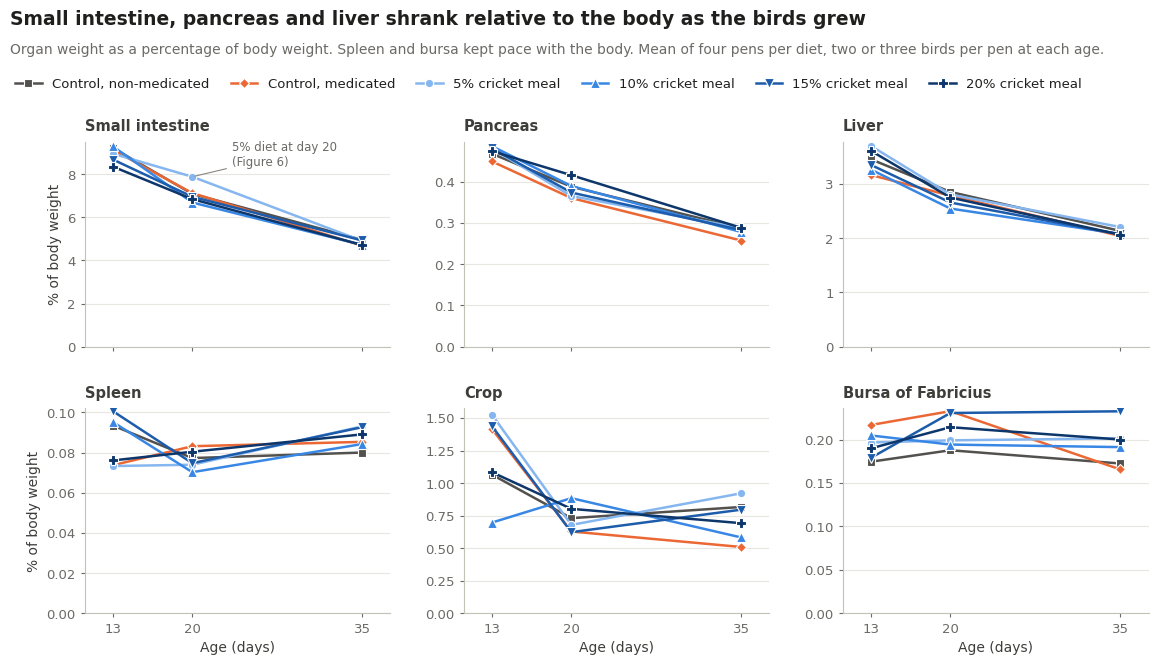

In [58]:
organ_titles = {"small_intestine": "Small intestine", "pancreas": "Pancreas", "liver": "Liver",
                "spleen": "Spleen", "crop": "Crop", "bursa": "Bursa of Fabricius"}
index_by_age = organ_pens.groupby(["diet", "day"], observed=True)[index_cols].mean()
ages = [13, 20, 35]

fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.6), sharex=True)
fig.subplots_adjust(left=0.065, right=0.99, top=0.80, bottom=0.085, wspace=0.24, hspace=0.30)

for ax, name in zip(axes.flat, organ_names):
    for diet in diet_order:
        ax.plot(ages, index_by_age.loc[diet, f"{name}_pct"], color=diet_colors[diet], marker=diet_markers[diet],
                markersize=marker_sizes[diet], markeredgecolor="white", markeredgewidth=0.8, linewidth=1.8, label=diet_labels[diet])
    panel_title(ax, organ_titles[name])
    # Every panel starts at zero, so that the height of a line shows the share of body weight honestly
    ax.set_ylim(0, None)
    ax.set_xticks(ages)
    ax.set_xlim(10.5, 37.5)
    ax.grid(axis="x", visible=False)
    ax.tick_params(length=3)

for ax in axes[1]:
    ax.set_xlabel("Age (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("% of body weight")

axes[0, 0].annotate("5% diet at day 20\n(Figure 6)", xy=(20, index_by_age.loc[("5% CM", 20), "small_intestine_pct"]),
                    xytext=(23.5, 8.9), fontsize=8.5, color=MUTED, va="center",
                    arrowprops={"arrowstyle": "-", "color": "#898781", "linewidth": 0.8})

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.0, 0.905), ncol=6, fontsize=9.5,
           handlelength=2.0, columnspacing=1.6, borderaxespad=0)
headline(fig, "Small intestine, pancreas and liver shrank relative to the body as the birds grew",
         "Organ weight as a percentage of body weight. Spleen and bursa kept pace with the body. Mean of four pens per diet, two or three birds per pen at each age.")
fig.savefig(FIGURE_DIR / "figure_5_organ_weights.png")
plt.show()

Small intestine, pancreas and liver take up a smaller share of the body at each age, in every diet. Spleen and bursa of Fabricius keep about the same share. The crop is erratic, which fits the wide spread of crop weights noted in section 5.4.

The six diets stay close together throughout. The clearest exception is the small intestine of the 5% CM diet at day 20, which Figure 6 looks at.

### Figure 6. The small intestine at day 20

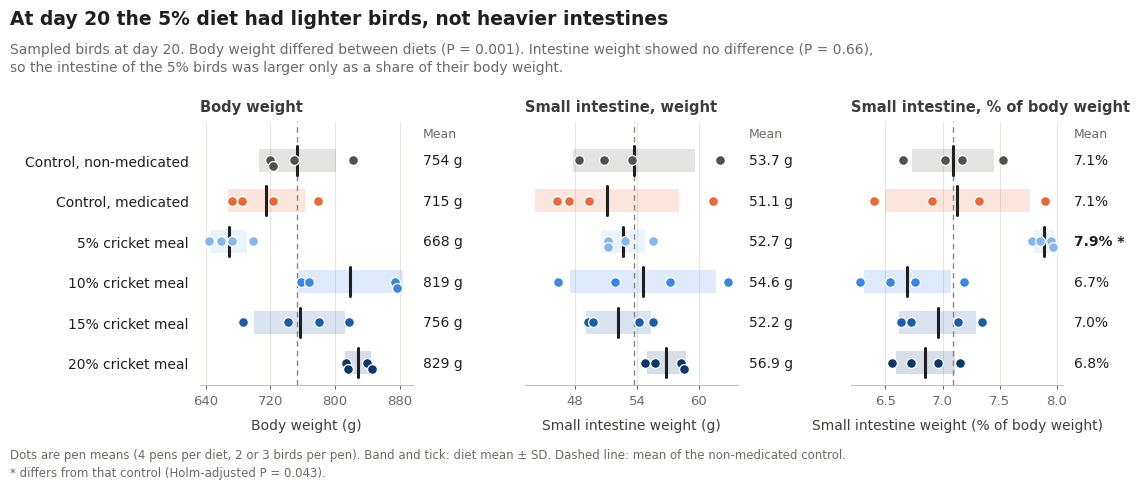

In [59]:
intestine_p = diet_means_table(intestine_day20, ["body_weight_g", "small_intestine_g"])["P"]
panels = [
    ("body_weight_g", "Body weight", "Body weight (g)", lambda value: f"{value:.0f} g", None),
    ("small_intestine_g", "Small intestine, weight", "Small intestine weight (g)", lambda value: f"{value:.1f} g", None),
    ("small_intestine_pct", "Small intestine, % of body weight", "Small intestine weight (% of body weight)",
     lambda value: f"{value:.1f}%", intestine_vs_control),
]

fig = plt.figure(figsize=(11.5, 4.7))
for i, (column, title, xlabel, fmt, comparisons) in enumerate(panels):
    ax = fig.add_axes([0.165 + i * 0.283, 0.20, 0.185, 0.56])
    diet_rows(ax, intestine_day20, column, fmt, comparisons=comparisons, diet_axis_labels=(i == 0))
    ax.set_xlabel(xlabel, labelpad=8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    panel_title(ax, title)

headline(fig, "At day 20 the 5% diet had lighter birds, not heavier intestines",
         f"Sampled birds at day 20. Body weight differed between diets (P = {intestine_p['body_weight_g']:.3f}). Intestine weight showed no difference "
         f"(P = {intestine_p['small_intestine_g']:.2f}),\nso the intestine of the 5% birds was larger only as a share of their body weight.")
footnote(fig, "Dots are pen means (4 pens per diet, 2 or 3 birds per pen). Band and tick: diet mean ± SD. Dashed line: mean of the non-medicated control.\n"
              f"* differs from that control (Holm-adjusted P = {intestine_vs_control.loc['5% CM', 'P (Holm)']:.3f}).")
fig.savefig(FIGURE_DIR / "figure_6_small_intestine_day20.png")
plt.show()

Left: at day 20 the sampled birds of the 5% CM diet were the lightest on average. Middle: their intestines weighed about the same as in the other diets. Right: one divided by the other gives the highest index, with all four 5% CM pens above every pen of the control. The 10 and 20% CM diets show the reverse: heavier birds, similar intestines and a lower index.

### Figure 7. Breast yield and cooking loss

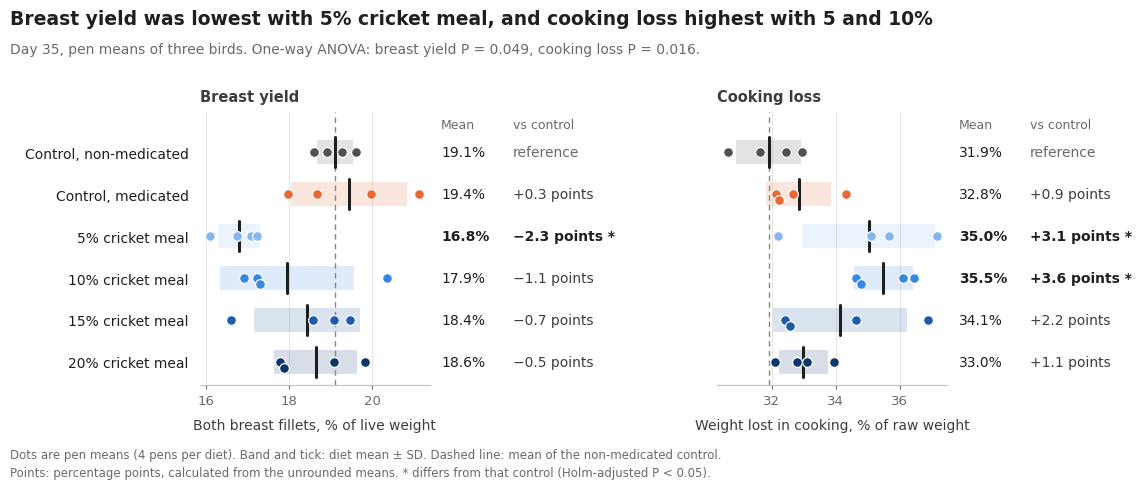

In [60]:
def in_points(difference):
    return f"{difference:+.1f} points"


fig = plt.figure(figsize=(11.5, 4.7))
ax_yield = fig.add_axes([0.165, 0.20, 0.20, 0.58])
ax_loss = fig.add_axes([0.615, 0.20, 0.20, 0.58])

diet_rows(ax_yield, meat_pens, "breast_yield_pct", lambda value: f"{value:.1f}%",
          comparisons=breast_yield_vs_control, change_fmt=in_points)
diet_rows(ax_loss, meat_pens, "cooking_loss_pct", lambda value: f"{value:.1f}%",
          comparisons=cooking_loss_vs_control, diet_axis_labels=False, change_fmt=in_points)

ax_yield.set_xlabel("Both breast fillets, % of live weight", labelpad=8)
ax_loss.set_xlabel("Weight lost in cooking, % of raw weight", labelpad=8)
panel_title(ax_yield, "Breast yield")
panel_title(ax_loss, "Cooking loss")

headline(fig, "Breast yield was lowest with 5% cricket meal, and cooking loss highest with 5 and 10%",
         f"Day 35, pen means of three birds. One-way ANOVA: breast yield P = {meat_tests.loc['breast_yield_pct', 'P']:.3f}, "
         f"cooking loss P = {meat_tests.loc['cooking_loss_pct', 'P']:.3f}.")
footnote(fig, "Dots are pen means (4 pens per diet). Band and tick: diet mean ± SD. Dashed line: mean of the non-medicated control.\n"
              "Points: percentage points, calculated from the unrounded means. * differs from that control (Holm-adjusted P < 0.05).")
fig.savefig(FIGURE_DIR / "figure_7_breast_yield_cooking_loss.png")
plt.show()

Left: all four pens of the 5% CM diet lie below every pen of the control. The 10% CM diet has three low pens and one high one, so its mean is not clearly different. Right: all four pens of the 10% CM diet lost more weight in cooking than any pen of the control, and so did three of the four 5% CM pens.

### Figure 8. Lesion scores

The scores are ordered, so they get one colour that darkens with the score, and grey for no lesions.

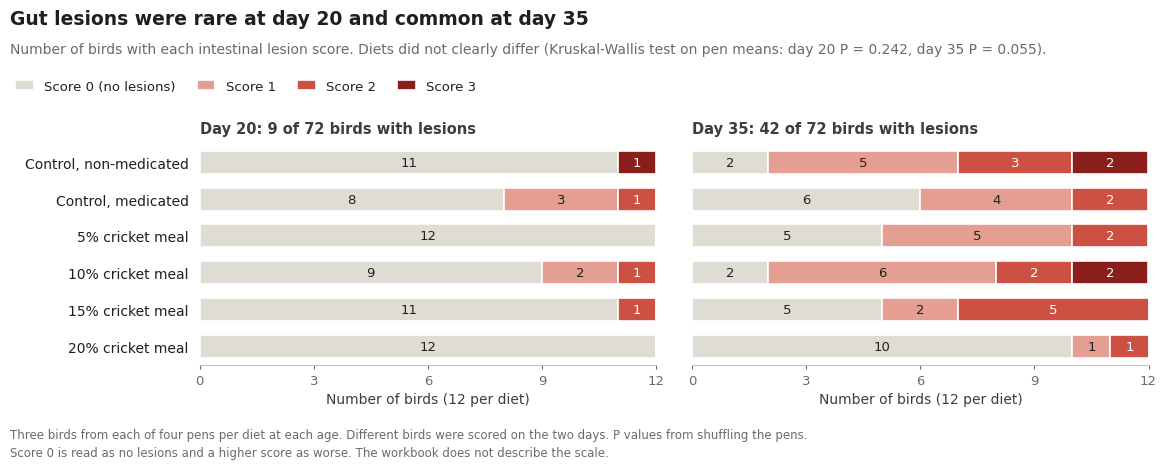

In [61]:
score_colors = {0: "#dedcd3", 1: "#e49f92", 2: "#cc5143", 3: "#8a1e1a"}
score_labels = {0: "Score 0 (no lesions)", 1: "Score 1", 2: "Score 2", 3: "Score 3"}
positions = np.arange(len(diet_order))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
fig.subplots_adjust(left=0.165, right=0.99, top=0.70, bottom=0.21, wspace=0.08)

for ax, day in zip(axes, (20, 35)):
    counts = score_counts.loc[day]
    start = np.zeros(len(diet_order))
    for score in counts.columns:
        n_birds = counts[score].to_numpy()
        ax.barh(positions, n_birds, left=start, height=0.62, color=score_colors[score], edgecolor="white", linewidth=1.2,
                label=score_labels[score])
        for position, (left_edge, n) in enumerate(zip(start, n_birds)):
            if n > 0:
                ax.text(left_edge + n / 2, position, str(n), ha="center", va="center", fontsize=9.5,
                        color="white" if score >= 2 else INK)
        start = start + n_birds
    n_with_lesions = int((lesion.loc[lesion["day"] == day, "score"] > 0).sum())
    panel_title(ax, f"Day {day}: {n_with_lesions} of {int(counts.to_numpy().sum())} birds with lesions")
    ax.set_xlim(0, 12)
    ax.set_xticks(range(0, 13, 3))
    ax.set_xlabel("Number of birds (12 per diet)")
    ax.grid(visible=False)
    ax.tick_params(axis="x", length=3)
    ax.tick_params(axis="y", length=0, pad=8)
    ax.spines["left"].set_visible(False)

axes[0].set_yticks(positions)
axes[0].set_yticklabels([diet_labels[diet] for diet in diet_order], color=INK, fontsize=10)
axes[0].set_ylim(len(diet_order) - 0.5, -0.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.0, 0.855), ncol=4, fontsize=9.5,
           columnspacing=1.6, handlelength=1.4, borderaxespad=0)
headline(fig, "Gut lesions were rare at day 20 and common at day 35",
         "Number of birds with each intestinal lesion score. Diets did not clearly differ "
         f"(Kruskal-Wallis test on pen means: day 20 P = {lesion_p[20]:.3f}, day 35 P = {lesion_p[35]:.3f}).")
footnote(fig, "Three birds from each of four pens per diet at each age. Different birds were scored on the two days. P values from shuffling the pens.\n"
              "Score 0 is read as no lesions and a higher score as worse. The workbook does not describe the scale.")
fig.savefig(FIGURE_DIR / "figure_8_lesion_scores.png")
plt.show()

Each bar is the 12 birds of one diet at one age. At day 20 most birds had no lesions (grey). At day 35 the grey part has shrunk in every diet. The 20% CM diet still had 10 of its 12 birds without lesions. The darkest colour, score 3, appears in the non-medicated control at both ages and in the 10% CM diet at day 35.

## 16. Main findings

**Did cricket meal change the birds' organs, gut lesions or breast meat?**

1. **Organs changed with age, hardly with diet.** Small intestine, pancreas and liver became smaller relative to the body as the birds grew, in every diet. Diet differences in organ indices and ileal pH appeared on days 13 and 20 and were gone by day 35 (no P below 0.08).
2. **The organ result singled out in the dataset description reflects lighter birds, not heavier intestines.** At day 20 the 5% CM diet had the highest small-intestine index (7.9% against 7.1% in the non-medicated control, Holm-adjusted P = 0.043). Intestine weight showed no difference between diets (P = 0.66). The 5% CM birds were 11% lighter, and that is what raised the index.
3. **Breast meat differed in two traits.** Breast yield was 16.8% of live weight in the 5% CM diet against 19.1% in the control (borderline, P = 0.049). Cooking loss was higher with 10% CM (35.5%) and 5% CM (35.0%) than in the control (31.9%, P = 0.016). Texture and colour showed no differences.
4. **Gut lesions rose with age, not clearly with diet.** 12.5% of birds had lesions at day 20 and 58.3% at day 35. At day 35 the 20% CM diet had the fewest (2 of 12 birds). The evidence for a diet effect at that age is borderline (P = 0.055).
5. **These sheets needed the same care as the growth sheet.** 21 supplied organ indices do not match the listed weights, 18 of them by a single digit. One row of a supplied frequency table does not match the listed scores. In the lesion sheet 112 pen numbers had to be restored, and three colour readings were set aside as errors. None of this shows without recalculating.

In short: by day 35, birds fed 10 to 20% cricket meal had organs and breast meat similar to the controls, apart from a higher cooking loss with 10% CM. Gut lesions showed no clear diet effect. The 5% CM diet, which also grew the slowest, had the lowest breast yield and a higher cooking loss.

## 17. Limitations

- **Few pens, small samples.** Four pens per diet and three birds per pen. Only large differences can be detected, and a pen mean of three birds is itself imprecise.
- **Many tests.** The three result tables hold 34 tests. Nine are below 0.05, against one or two expected if no diet had any effect (a rough guide, because the tests are not independent). A single result close to 0.05 (breast yield, pancreas index and pH at day 20) may be a false alarm.
- **Sex.** On days 13 and 20 the sampled birds were not balanced for sex. A pen gave anything from three females to three males on day 13, and from two females and one male to three males on day 20. Males are heavier, so this adds noise to the early results and could shift a diet mean. At day 35 every pen gave one female and two males.
- **Indices and body weight.** An index mixes organ weight and body weight. On days 13 and 20 body weight differed between diets, so index differences at those ages are hard to interpret (section 12.3).
- **Which number is right.** Where a supplied index and a listed weight disagree, I used the listed weight. For those 21 cells, for the spleen weight and for the three colour readings that were set aside, only the original records could settle it.
- **Crop.** Crop weights vary more than those of any other organ, and the workbook does not say whether crops were weighed with their contents.
- **Lesion scores.** The scoring scale is not described in the workbook. I assumed that 0 means no lesions and that higher scores are worse. The scores are ordered categories from three birds per pen, which gives a coarse measure per pen. The diet comparison at day 35 is borderline (P = 0.055), so it neither shows nor rules out a diet effect.
- **Not the published analysis.** As in the first notebook, the tests are simple checks on pen means and may differ from the models used in the article.

## 18. Reproducibility information

The notebook runs from top to bottom with no manual steps other than providing the workbook. The only random numbers are the shuffles of section 14. They always start from the same point (a fixed seed), so every run gives the same tables and figures. The SHA-256 printed in section 4 is a fingerprint of the file. The same value means that exactly the same workbook was analysed.

In [62]:
print("Python    ", platform.python_version())
for module in (pd, np, matplotlib, scipy, openpyxl):
    print(f"{module.__name__:10s}", module.__version__)

Python     3.12.3
pandas     2.2.2
numpy      2.0.2
matplotlib 3.10.0
scipy      1.16.3
openpyxl   3.1.5
